# Reto 7: Detector de Regímenes de Mercado
## Examen final (v7): los modelos A y B en el tramo reservado del S&P 500 (2022 – septiembre 2026)

**Equipo:** Samuel Gómez Jiménez (744337) · Ana Paula Moreno Haro (744069) · Andrea Santoyo Vega (744585)
Laboratorio de Desarrollo de Soluciones Tecnológicas · ITESO · Otoño 2026

### De qué trata

Desde el Reporte 1 apartamos los datos de enero de 2022 a septiembre de 2026 y no los usamos para decidir nada: ni el modelo, ni las reglas, ni los umbrales. Este notebook los abre **una sola vez** para evaluar los dos modelos que congelamos en el Reporte 5 (huella de la regla `897fd3d539`):

| | Idea en una frase | Cómo invierte |
|---|---|---|
| **Modelo A** | "Sal del mercado cuando esté agitado" | 100% en el índice, o 100% en T-bills cuando la volatilidad pronosticada pasa del umbral bajista (16.4%) |
| **Modelo B** | "Invierte menos mientras más agitado esté" | Una fracción del índice igual a 13.5% / volatilidad pronosticada (máximo 100%); el resto, en T-bills |

### Qué cambió respecto al v6.1 (sólo esto)

Este notebook **sustituye al v6.1**: lo contiene completo, así que el v6.1 ya no se corre por separado.


1. `EVALUAR_RESERVADO = True` en A.1.
2. La celda D.3 se sustituye por la **sección E**. El detector ya no se reinicia en 2022: la cadena de reestimaciones sigue sin cortes desde 1990, y se verifica que 1990–2021 sea idéntico al v5.1 (desviación declarada en E). La sección E declara las hipótesis antes de correr (con su propia huella), registra cada apertura del tramo reservado, evalúa A y B con la prueba pareada, el PSR y el Sharpe deflactado, analiza cada episodio de caída y emite un veredicto por hipótesis.
3. Al final se guarda `resultados_reservado_v7.pkl`, con el tramo reservado y el desarrollo de A, B y comprar y mantener. Lo usa `03_Comparativa_Multiactivo` para comparar el S&P con los demás índices.

**Las secciones A a D no cambian.** Deben reproducir exactamente las cifras del Reporte 5 (huella de datos `ab3ae2b8c6`, regla `897fd3d539`). Si algo no coincide, el notebook se detiene antes de abrir el tramo reservado.

### Resultados del desarrollo (1990–2021, con costos; Reporte 5)

| | Valor final de $1,000 | Rendimiento anual | Volatilidad anual | Sharpe | Caída máxima |
|---|---|---|---|---|---|
| Comprar y mantener | $13,487 | 8.5% | 18.1% | 0.40 | −56.8% |
| **Modelo B** | $8,965 | 7.1% | 13.0% | **0.40** | **−38.9%** |
| **Modelo A** | $4,531 | 4.8% | 10.3% | 0.26 | −30.1% |

Los resultados del tramo reservado están en la sección E.

### Cómo correrlo

- Es el **segundo** en el orden de corrida. Va en la misma carpeta que `resultados_v5.pkl`, que genera `01_Prototipo_Exploratorio_v5.1`. **Kernel → Restart & Run All, una sola vez.** Las secciones A a D tardan lo mismo que el v6.1; la sección E vuelve a correr la cadena del detector desde 1990 (unas 440 reestimaciones, del orden de 15 a 30 minutos).
- **Antes de correr**, copien las hipótesis de E.0 al reporte. Su huella se imprime al correr y debe coincidir con la del reporte.
- Cada apertura queda anotada en `aperturas_reservado.log`. Si por cualquier razón se corre más de una vez, se declara en el reporte cuántas veces y por qué.


# A. Preparación (técnica)

Esta sección no presenta resultados. Fija la configuración, descarga los mismos datos del v5.1 y carga lo que el v5.1 ya estimó, para no volver a estimar nada. Cada paso verifica que todo coincida con el Reporte 4 y, si no, el notebook se detiene.

## A.1 Configuración

`CONFIG` se hereda sin cambios del v5.1. `MODELOS` contiene las decisiones nuevas de este notebook, todas fijadas antes de ver resultados.


In [1]:
import hashlib, json, pickle, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from IPython.display import display
import yfinance as yf
warnings.filterwarnings("ignore", category=RuntimeWarning)

EVALUAR_RESERVADO = True    # examen final: se abre UNA sola vez [6]
ARCHIVO_V5 = "resultados_v5.pkl"

with open(ARCHIVO_V5, "rb") as f:
    V5 = pickle.load(f)
CONFIG = V5["CONFIG"]                                   # heredada del v5.1 sin cambios
assert not V5["evaluar_reservado"], "El archivo del v5.1 se guardó con el reservado abierto"

# Decisiones nuevas, declaradas en el Reporte 4 y fijadas aquí ANTES de ver cualquier resultado
MODELOS = {
    "inversion_inicial": 1000,                          # dólares
    "costo": 0.001,                                     # 0.1% por unidad de |Δw| [9]
    "horizonte": 1 + CONFIG["rezago"],                  # la posición decidida al cierre de t gana el rendimiento de t + 2
    # Modelo A: etiquetas ancladas a la escala de 1950–1989
    "umbrales": "media geométrica de las volatilidades de regímenes vecinos del modelo de 1950–1989",
    "A": {"posicion": {"alcista": 1.0, "base": 1.0, "bajista": 0.0},   # sin corto; base invertido (desviación declarada, ver B.2)
          "dias_salir": 3, "dias_volver": 1},                          # reentrada rápida
    "A_original": {"posicion": {"alcista": 1.0, "base": 0.0, "bajista": 0.0}},   # la declarada en el Reporte 4: sólo en la bitácora
    # Modelo B: exposición por volatilidad pronosticada [15]
    "B": {"vol_objetivo": 0.135, "tope": 1.0,           # sin apalancamiento: B sólo puede reducir la exposición
          "banda": 0.10},                               # rebalancea si el peso objetivo se aleja más de 10 puntos (o toca el tope)
}
INICIAL, COSTO, H = MODELOS["inversion_inicial"], MODELOS["costo"], MODELOS["horizonte"]
N, NOMBRES, SEM = CONFIG["N"], ["alcista", "base", "bajista"], CONFIG["semilla"]
DIST, PRINCIPAL = V5["DIST"], V5["PRINCIPAL"]

C_REG = {"alcista": "#1baf7a", "base": "#a3a29c", "bajista": "#e34948"}
C_EST = {"Prototipo (Reporte 4)": "#2a78d6", "Prototipo sin corto": "#6250d6",
         "A0 anclado con corto": "#9ecae1", "A1 anclado sin corto": "#4292c6", "A original (Reporte 4)": "#2171b5", "Modelo A": "#08306b",
         "Modelo B": "#c2185b", "B sin banda": "#f48fb1",
         "Comprar y mantener": "#52514e", "Markov observable 1er orden": "#eb6834"}
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10, "legend.frameon": False})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
print(f"Tramo reservado {'ABIERTO' if EVALUAR_RESERVADO else 'bloqueado'} | resultados heredados: {V5['version']} | "
      f"modelo: HMM {DIST}, N = {N} | Python {sys.version.split()[0]}")


Tramo reservado ABIERTO | resultados heredados: v5.1 | modelo: HMM t, N = 3 | Python 3.12.10


## A.2 Datos

S&P 500 y tasa del T-bill a 13 semanas desde 1950. La huella comprueba que son exactamente los mismos datos del v5.1.


In [2]:
def descargar(ticker, inicio=CONFIG["inicio"]):
    serie = yf.download(ticker, start=inicio, end=pd.Timestamp(CONFIG["fin"]) + pd.Timedelta(days=1),
                        auto_adjust=False, progress=False)["Close"]
    serie = serie.squeeze("columns") if isinstance(serie, pd.DataFrame) else serie
    serie.index = pd.to_datetime(serie.index).tz_localize(None)
    return serie.dropna().sort_index()


precio = descargar(CONFIG["ticker"])
try:
    tasa = descargar(CONFIG["ticker_tasa"])
    rf_todo = tasa.reindex(precio.index).ffill().bfill() / 100 / 252
except Exception as e:
    print("No se pudo descargar la tasa del T-bill; se usa 0:", e); rf_todo = pd.Series(0.0, index=precio.index)

x_serie = np.log(precio).diff().dropna()
x, fechas = x_serie.values, x_serie.index
r_simple = precio.pct_change().reindex(fechas)
rf = rf_todo.reindex(fechas).fillna(0.0)
i_des = fechas.searchsorted(pd.Timestamp(CONFIG["inicio_desarrollo"]))
i_res = fechas.searchsorted(pd.Timestamp(CONFIG["inicio_reservado"]))
ini, fin = fechas[i_des], fechas[i_res - 1]
huella = hashlib.md5(np.round(precio.values, 2).tobytes()).hexdigest()[:10]
assert huella == V5["huella"], f"La huella {huella} no coincide con la del v5.1 ({V5['huella']})"
print(f"S&P 500: {len(x):,} rendimientos | huella {huella} (coincide con el v5.1) | "
      f"desarrollo {ini:%Y-%m-%d} a {fin:%Y-%m-%d}")


S&P 500: 19,307 rendimientos | huella ab3ae2b8c6 (coincide con el v5.1) | desarrollo 1990-01-02 a 2021-12-31


## A.3 Funciones heredadas del v5.1

El código del HMM, de la estimación móvil y del Sharpe deflactado, sin cambios. El modelo sólo se vuelve a estimar en D.3, para el tramo reservado.


In [3]:
def acotar_extremos(v, k=6):
    if k is None:
        return v
    m, s = v.mean(), v.std()
    return np.clip(v, m - k * s, m + k * s)


def nombres_regimen(N):
    return ["alcista", "base", "bajista"] if N == 3 else ["alcista", "bajista"]


def densidades(x, mu, sigma, nu, dist):
    z = (x[:, None] - mu) / sigma
    if dist == "normal":
        return stats.norm.pdf(z) / sigma + 1e-300
    return stats.t.pdf(z, df=nu) / sigma + 1e-300


def forward(dens, A, pi):
    T, N = dens.shape
    alfa, c = np.zeros((T, N)), np.zeros(T)
    a = pi * dens[0]
    c[0] = a.sum(); alfa[0] = a / c[0]
    for t in range(1, T):
        a = (alfa[t - 1] @ A) * dens[t]
        c[t] = a.sum(); alfa[t] = a / c[t]
    return alfa, c, np.log(c).sum()


def backward(dens, A, c):
    T, N = dens.shape
    beta = np.ones((T, N))
    for t in range(T - 2, -1, -1):
        beta[t] = (A @ (dens[t + 1] * beta[t + 1])) / c[t + 1]
    return beta


def ajustar_hmm(x, N, dist="t", semilla=0, inicio=None, pesos=None, max_iter=500, tol=1e-7):
    rng = np.random.default_rng(semilla)
    w = np.ones(len(x)) if pesos is None else pesos
    if inicio is None:
        sigma = np.sort(x.std() * rng.uniform(0.4, 1.6, N))
        mu = rng.normal(0, x.std() * 0.1, N)
        A = np.full((N, N), 0.04 / (N - 1)) + np.eye(N) * (0.96 - 0.04 / (N - 1))
        pi, nu = np.full(N, 1 / N), np.full(N, 8.0)
    else:
        mu, sigma, nu, A, pi = [np.array(inicio[k], dtype=float) for k in ("mu", "sigma", "nu", "A", "pi")]
    ll_prev = -np.inf
    for it in range(max_iter):
        dens = densidades(x, mu, sigma, nu, dist)
        alfa, c, ll = forward(dens, A, pi)
        beta = backward(dens, A, c)
        gamma = alfa * beta
        xi = alfa[:-1, :, None] * A[None] * (dens[1:] * beta[1:])[:, None, :] / c[1:, None, None]
        g, xw = gamma * w[:, None], xi * w[1:, None, None]
        pi = gamma[0]
        A = xw.sum(0) / xw.sum(0).sum(1, keepdims=True)
        u = (nu + 1) / (nu + ((x[:, None] - mu) / sigma) ** 2) if dist == "t" else np.ones_like(g)
        mu = (g * u * x[:, None]).sum(0) / (g * u).sum(0)
        sigma = np.maximum(np.sqrt((g * u * (x[:, None] - mu) ** 2).sum(0) / g.sum(0)), 1e-4)
        if dist == "t":
            for i in range(N):
                f = lambda v: -(g[:, i] * stats.t.logpdf((x - mu[i]) / sigma[i], df=v)).sum()
                nu[i] = optimize.minimize_scalar(f, bounds=(2.1, 40), method="bounded").x
        if abs(ll - ll_prev) < tol * abs(ll):
            break
        ll_prev = ll
    _, _, ll = forward(densidades(x, mu, sigma, nu, dist), A, pi)
    return ordenar({"mu": mu, "sigma": sigma, "nu": nu, "A": A, "pi": pi, "ll": ll, "dist": dist, "N": N, "iter": it + 1})


def ordenar(m):
    o = np.argsort(m["sigma"] * (np.sqrt(m["nu"] / (m["nu"] - 2)) if m["dist"] == "t" else 1))
    m = dict(m)
    for k in ("mu", "sigma", "nu", "pi"):
        m[k] = m[k][o]
    m["A"] = m["A"][np.ix_(o, o)]
    return m


def desv_estandar(m):
    return m["sigma"] * (np.sqrt(m["nu"] / (m["nu"] - 2)) if m["dist"] == "t" else 1)


def filtrar(x, m):
    return forward(densidades(x, m["mu"], m["sigma"], m["nu"], m["dist"]), m["A"], m["pi"])[0]


def prueba_movil(dist, n_reg, inicio, fin, W, R):
    """Estimación móvil del v5.1 (ventana dura). Sólo se usa en D.3 para el tramo reservado."""
    nombres = nombres_regimen(n_reg)
    prob_, registro, m = np.full((fin - inicio, n_reg), np.nan), [], None
    for r in range(inicio, fin, R):
        datos = acotar_extremos(x[r - W:r], CONFIG["acotar_extremos"])
        if m is None:
            candidatos = [ajustar_hmm(datos, n_reg, dist, semilla=SEM + s) for s in range(CONFIG["n_inicializaciones"])]
        else:
            candidatos = [ajustar_hmm(datos, n_reg, dist, inicio=m)]
            if (r - inicio) % CONFIG["reinicios_cada"] < R:
                candidatos += [ajustar_hmm(datos, n_reg, dist, semilla=SEM + r + s) for s in range(2)]
        m = max(candidatos, key=lambda c: c["ll"])
        hasta = min(r + R, fin)
        prob_[r - inicio:hasta - inicio] = filtrar(x[r - W:hasta], m)[W:]
        registro.append({"fecha": fechas[r],
                         **{f"vol {n}": v for n, v in zip(nombres, desv_estandar(m) * np.sqrt(252))},
                         **{f"rend {n}": v for n, v in zip(nombres, m["mu"] * 252)},
                         **{f"A {i}{j}": m["A"][i, j] for i in range(n_reg) for j in range(n_reg)}})
    return (pd.DataFrame(prob_, index=fechas[inicio:fin], columns=nombres),
            pd.DataFrame(registro).set_index("fecha"))


POS = np.array([CONFIG["posicion"][n] for n in NOMBRES])                     # prototipo: 1, 0, −0.5
POS2 = np.array([CONFIG["posicion"]["alcista"], CONFIG["posicion"]["bajista"]])
sin_corto = lambda p: np.where(p < 0, 0.0, p)


def posicion_detector(p, k=CONFIG["dias_confirmacion"], posiciones=None):
    """Regla del prototipo (v5.1): confirmación simétrica de k días. Se usa para reconstruir la bitácora."""
    posiciones = (POS if p.shape[1] == 3 else POS2) if posiciones is None else posiciones
    mas_probable = p.values.argmax(1)
    w = np.zeros(len(mas_probable)); actual = posiciones[mas_probable[0]]
    for t in range(len(mas_probable)):
        if t >= k - 1 and np.all(mas_probable[t - k + 1:t + 1] == mas_probable[t]):
            actual = posiciones[mas_probable[t]]
        w[t] = actual
    return pd.Series(w, index=p.index)


def posicion_markov(orden, W=CONFIG["ventana"]):
    sube = (x_serie > 0).astype(int)
    estado = sube if orden == 1 else 2 * sube.shift(1) + sube
    p_sube = pd.Series(np.nan, index=fechas)
    for e in range(2 ** orden):
        en_e = (estado.shift(1) == e)
        prob_e = (en_e & (sube == 1)).astype(int).rolling(W).sum() / en_e.astype(int).rolling(W).sum()
        p_sube[estado == e] = prob_e[estado == e]
    return (p_sube > 0.5).astype(float)


def ee_sharpe(ex):
    sr = ex.mean() / ex.std()
    var = (1 - stats.skew(ex) * sr + (stats.kurtosis(ex, fisher=False) - 1) / 4 * sr ** 2) / (len(ex) - 1)
    return np.sqrt(var * 252)


def psr(ex):
    """Probabilidad de que el Sharpe verdadero sea mayor que cero, con una sola prueba [14]."""
    sr = ex.mean() / ex.std()
    den = np.sqrt(1 - stats.skew(ex) * sr + (stats.kurtosis(ex, fisher=False) - 1) / 4 * sr ** 2)
    return stats.norm.cdf(sr * np.sqrt(len(ex) - 1) / den)


def sharpe_deflactado(ex, todas):
    """PSR y DSR de Bailey y López de Prado [14]."""
    T, sr = len(ex), ex.mean() / ex.std()
    g3, g4 = stats.skew(ex), stats.kurtosis(ex, fisher=False)
    srs = todas.mean() / todas.std()
    M = todas.shape[1]
    corr = todas.corr().values
    rho = corr[np.triu_indices(M, 1)].mean()
    N_ef = rho + (1 - rho) * M
    gam = 0.5772156649
    sr0 = np.sqrt(srs.var()) * ((1 - gam) * stats.norm.ppf(1 - 1 / N_ef) + gam * stats.norm.ppf(1 - 1 / (N_ef * np.e)))
    den = np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)
    psr0 = stats.norm.cdf(sr * np.sqrt(T - 1) / den)
    dsr = stats.norm.cdf((sr - sr0) * np.sqrt(T - 1) / den)
    return {"Sharpe diario": sr, "Sharpe anual": sr * np.sqrt(252), "pruebas (M)": M, "correlación media": rho,
            "pruebas efectivas": N_ef, "umbral SR0 diario": sr0, "PSR (Sharpe > 0)": psr0, "DSR": dsr}


**Dos funciones con un agregado.** `evaluar()` ahora descuenta el costo de transacción: $R_t = w_t r_t + (1 - |w_t|)\, r^f_t - c\,|w_t - w_{t-1}|$, donde $w_t$ es la fracción invertida en el índice. Con $c = 0$ da exactamente lo mismo que en el v5.1. `metricas()` agrega el valor final de los $1,000, la rotación anual y la exposición media. `tabla()` sólo da formato legible a las tablas.


In [4]:
def evaluar(w_decidida, desde, hasta, costo=0.0):
    """Rezago de la señal (decide al cierre de t, ejecuta al cierre de t+1) y costo por |Δw|."""
    w = w_decidida.reindex(fechas).shift(1 + CONFIG["rezago"])[desde:hasta].fillna(1.0)
    rs, rft = r_simple[w.index], rf[w.index]
    ret = w * rs + (1 - w.abs()) * rft - costo * w.diff().abs().fillna(0.0)
    return ret, ret - rft, w


def metricas(ret, ex, w):
    riqueza = (1 + ret).cumprod()
    return {"valor final": INICIAL * riqueza.iloc[-1], "rend. anual": riqueza.iloc[-1] ** (252 / len(ret)) - 1,
            "vol. anual": ret.std() * np.sqrt(252), "Sharpe": ex.mean() / ex.std() * np.sqrt(252), "EE Sharpe": ee_sharpe(ex),
            "caída máxima": (riqueza / riqueza.cummax() - 1).min(),
            "cambios de posición": int((w.diff().abs() > 0).sum()), "rotación anual": w.diff().abs().sum() / (len(w) / 252),
            "exposición media": w.mean(), "% comprado": (w > 0).mean(), "% T-bill": (w == 0).mean(), "% corto": (w < 0).mean()}


FMT_RES = {"valor final": "${:,.0f}", "rend. anual": "{:.1%}", "vol. anual": "{:.1%}", "Sharpe": "{:.2f}", "EE Sharpe": "{:.2f}",
           "caída máxima": "{:.1%}", "cambios de posición": "{:.0f}", "rotación anual": "{:.1f}", "exposición media": "{:.0%}",
           "% comprado": "{:.0%}", "% T-bill": "{:.0%}", "% corto": "{:.0%}"}


ETIQ = {"valor final": "Valor final de $1,000", "rend. anual": "Rendimiento anual", "vol. anual": "Volatilidad anual",
        "Sharpe": "Sharpe", "EE Sharpe": "Error estándar del Sharpe", "caída máxima": "Caída máxima",
        "cambios de posición": "Cambios de posición", "rotación anual": "Rotación anual", "exposición media": "Exposición media",
        "% comprado": "Días en el índice", "% T-bill": "Días en T-bills", "% corto": "Días en corto"}


def tabla(df, cols, resaltar=()):
    """Tabla con nombres legibles; 'resaltar' marca en negritas las filas indicadas."""
    t = df[cols].rename(columns=ETIQ)
    st = t.style.format({ETIQ[c]: FMT_RES[c] for c in cols})
    return st.apply(lambda r: ["font-weight: bold" if r.name in resaltar else "" for _ in r], axis=1)


def grafica_valor(ax, series, titulo, resaltar=()):
    """Valor de la inversión en dólares (escala normal) con una etiqueta del valor final de cada estrategia."""
    riq = {n: INICIAL * (1 + ret).cumprod() for n, ret in series.items()}
    for n, w in riq.items():
        ax.plot(w, color=C_EST[n], lw=2.4 if n in resaltar else 1.2, label=n)
    x0, x1 = min(w.index[0] for w in riq.values()), max(w.index[-1] for w in riq.values())
    ymax = max(w.max() for w in riq.values()) * 1.05
    rango = ymax - (0 if min(w.min() for w in riq.values()) < 0.4 * ymax else min(w.min() for w in riq.values()) * 0.95)
    sep, ult, pos = rango * 0.06, -np.inf, {}
    for n in sorted(riq, key=lambda k: riq[k].iloc[-1]):          # de menor a mayor, separadas para que no se encimen
        pos[n] = ult = max(riq[n].iloc[-1], ult + sep)
    for n, y in pos.items():
        ax.annotate(f"${riq[n].iloc[-1]:,.0f}", xy=(riq[n].index[-1], riq[n].iloc[-1]), xytext=(x1 + (x1 - x0) * 0.015, y),
                    color=C_EST[n], fontsize=9, fontweight="bold", va="center", annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", color=C_EST[n], lw=0.6))
    ax.set_xlim(x0, x1 + (x1 - x0) * 0.09)
    ymin = min(w.min() for w in riq.values())
    piso = 0 if ymin < 0.4 * ymax else ymin * 0.95              # tramos cortos: no se aplasta la gráfica contra el cero
    ax.set_ylim(piso, max(ymax, max(pos.values()) + sep))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    ax.set_title(titulo); ax.legend(loc="upper left" if piso == 0 else "best", fontsize=9)


## A.4 Resultados heredados del v5.1

Se cargan las probabilidades y los parámetros de la estimación móvil, el modelo de 1950–1989 y los episodios de crisis. Como control, se reconstruye la bitácora del Reporte 4 (44 pruebas): debe dar exactamente los mismos Sharpe y el mismo Sharpe deflactado (0.33).


In [5]:
prob, params = V5["prob"], V5["params"]
modelo_est, ruta, episodios = V5["modelo_est"], V5["ruta"], V5["episodios"]
assert all(p.index[-1] <= fin for p in prob.values()), "Hay probabilidades del tramo reservado en el archivo"
assert all(f"A {i}{j}" in params[PRINCIPAL] for i in range(N) for j in range(N)), "El archivo no trae la matriz A (usa el v5.1)"


def bitacora_v5(costo):
    """Reconstruye las 44 pruebas del Reporte 4 (mismo orden y nombres que el v5.1), con o sin costos."""
    filas, ex = {}, {}
    for nombre_v in prob:
        base_pos = POS if prob[nombre_v].shape[1] == 3 else POS2
        for k in [1, 3, 5]:
            for corto in ["con corto", "sin corto"]:
                posiciones = base_pos if corto == "con corto" else sin_corto(base_pos)
                prueba = f"HMM {nombre_v} | k={k} | {corto}"
                ret, e, w = evaluar(posicion_detector(prob[nombre_v], k, posiciones), ini, fin, costo)
                ex[prueba], filas[prueba] = e, metricas(ret, e, w)
    for n_, orden_ in [("Markov observable 1er orden", 1), ("Markov observable 2o orden", 2)]:
        ret, e, w = evaluar(posicion_markov(orden_), ini, fin, costo)
        ex[n_], filas[n_] = e, metricas(ret, e, w)
    return pd.DataFrame(filas).T, pd.DataFrame(ex)


bit_v5_sc, ex_v5_sc = bitacora_v5(0.0)
bit_v5_cc, ex_v5_cc = bitacora_v5(COSTO)
dif = (bit_v5_sc["Sharpe"] - V5["bitacora"].loc[bit_v5_sc.index, "Sharpe"]).abs().max()
dsr_check = sharpe_deflactado(ex_v5_sc[V5["principal_bitacora"]], ex_v5_sc)["DSR"]
assert dif < 1e-9 and abs(dsr_check - V5["dsr"]["DSR"]) < 1e-9, "La bitácora reconstruida no coincide con la del v5.1"
print(f"Bitácora del Reporte 4 reconstruida: {len(bit_v5_sc)} pruebas | diferencia máxima de Sharpe {dif:.1e} | "
      f"DSR de la regla principal {dsr_check:.2f} (igual al v5.1)")


Bitácora del Reporte 4 reconstruida: 44 pruebas | diferencia máxima de Sharpe 0.0e+00 | DSR de la regla principal 0.33 (igual al v5.1)


# B. Construcción de los modelos

Esta sección sólo define funciones y valores fijos. Ningún número de aquí depende de los resultados de 1990–2021.

## B.1 Volatilidad pronosticada y etiquetas ancladas

**Volatilidad pronosticada.** Cada día, el detector conoce la probabilidad filtrada $p_t$ de cada régimen y los parámetros vigentes (los de la última reestimación). La posición que se decide al cierre de $t$ gana el rendimiento de $t + h$, con $h = 2$ por el rezago de ejecución, así que se proyecta $q_t = p_t A^h$ y se calcula la desviación estándar de la mezcla:

$$\hat\sigma_{t+h} = \sqrt{\textstyle\sum_k q_{t,k}\,(\sigma_k^2 + \mu_k^2) - \left(\sum_k q_{t,k}\,\mu_k\right)^2}\ \cdot \sqrt{252}$$

donde $\sigma_k$ es la desviación estándar del régimen $k$ (en la t, corregida por $\nu_k$). Los dos modelos usan la misma $\hat\sigma$: A la corta en escalones y B la usa de forma continua.

**Etiquetas ancladas (modelo A).** En lugar de ordenar los regímenes dentro de cada ventana, cada día se etiqueta por su $\hat\sigma$ contra dos umbrales fijos, la media geométrica de las volatilidades de regímenes vecinos del modelo de 1950–1989 (Tabla I del Reporte 4). Así no hay colisiones (dos regímenes de una ventana con la misma etiqueta) y "bajista" significa lo mismo en 1996 que en 2008.


In [6]:
VOL_EST = desv_estandar(modelo_est) * np.sqrt(252)               # alcista, base, bajista (1950–1989)
UMBRALES = np.sqrt(VOL_EST[:-1] * VOL_EST[1:])                    # alcista | base | bajista
print("Volatilidad anual de cada régimen, modelo de 1950–1989: " + ", ".join(f"{n} {v:.1%}" for n, v in zip(NOMBRES, VOL_EST)))
print(f"Umbrales anclados: alcista por debajo de {UMBRALES[0]:.1%}, bajista por encima de {UMBRALES[1]:.1%}")


def vol_pronosticada(p, pr, h=H):
    """σ̂ anual para t + h con los parámetros vigentes cada día (los de la última reestimación)."""
    n = p.shape[1]; nombres = list(p.columns)
    par = pr.reindex(p.index, method="ffill")
    mu = par[[f"rend {k}" for k in nombres]].values / 252
    sd = par[[f"vol {k}" for k in nombres]].values / np.sqrt(252)
    A_t = par[[f"A {i}{j}" for i in range(n) for j in range(n)]].values.reshape(-1, n, n)
    q = p.values
    for _ in range(h):
        q = np.einsum("ti,tij->tj", q, A_t)
    m1, m2 = (q * mu).sum(1), (q * (sd ** 2 + mu ** 2)).sum(1)
    return pd.Series(np.sqrt(np.maximum(m2 - m1 ** 2, 0)) * np.sqrt(252), index=p.index)


def etiqueta_anclada(sig):
    return pd.Series(np.digitize(sig.values, UMBRALES), index=sig.index)     # 0 alcista, 1 base, 2 bajista


def etiqueta_relativa(p):
    return pd.Series(p.values.argmax(1), index=p.index)                      # la del prototipo


sig = vol_pronosticada(prob[PRINCIPAL], params[PRINCIPAL])
et_anc, et_rel = etiqueta_anclada(sig), etiqueta_relativa(prob[PRINCIPAL])


Volatilidad anual de cada régimen, modelo de 1950–1989: alcista 6.9%, base 11.9%, bajista 22.6%
Umbrales anclados: alcista por debajo de 9.0%, bajista por encima de 16.4%


## B.2 Regla del modelo A: confirmación asimétrica

La posición objetivo de cada día sale de la etiqueta. Si el objetivo **baja** la exposición (salir), se cambia sólo cuando lleva `dias_salir` = 3 días seguidos; si la **sube** (volver), basta `dias_volver` = 1. Con 3 y 3 es exactamente la regla del prototipo, y la celda lo verifica.


In [7]:
def posicion_asimetrica(etiqueta, posiciones, k_salir, k_volver):
    objetivo = np.asarray(posiciones)[np.asarray(etiqueta)]
    w = np.zeros(len(objetivo)); actual = objetivo[0]; racha = 0
    for t in range(len(objetivo)):
        racha = racha + 1 if t > 0 and objetivo[t] == objetivo[t - 1] else 1   # días seguidos con el mismo objetivo
        k = k_salir if objetivo[t] < actual else k_volver
        if objetivo[t] != actual and racha >= k:
            actual = objetivo[t]
        w[t] = actual
    return pd.Series(w, index=etiqueta.index)


assert np.allclose(posicion_asimetrica(et_rel, POS, 3, 3), posicion_detector(prob[PRINCIPAL])), "No reproduce al prototipo"
POS_A = np.array([MODELOS["A"]["posicion"][n] for n in NOMBRES])
POS_A_ORIG = np.array([MODELOS["A_original"]["posicion"][n] for n in NOMBRES])
print(f"Posiciones del modelo A: {dict(zip(NOMBRES, POS_A))} | salir {MODELOS['A']['dias_salir']} días, "
      f"volver {MODELOS['A']['dias_volver']} | con 3 y 3 reproduce al prototipo: sí")


Posiciones del modelo A: {'alcista': np.float64(1.0), 'base': np.float64(1.0), 'bajista': np.float64(0.0)} | salir 3 días, volver 1 | con 3 y 3 reproduce al prototipo: sí


### Desviación declarada: el modelo A invierte en el régimen base

El Reporte 4 declaró para el modelo A las posiciones alcista 100%, base T-bills y bajista T-bills. Antes de correr este notebook con los datos reales cambiamos la del régimen base a **100% en el índice**: el modelo A sólo sale del mercado cuando la etiqueta anclada es bajista. Las razones son de diseño, no de resultados:

1. **Anclar las etiquetas cambió lo que significa "base".** En el prototipo, base era el régimen intermedio *de cada ventana*. Con las etiquetas ancladas, base es el rango de volatilidad normal del mercado, entre 9% y 16% anual aproximadamente (B.1), donde cae la volatilidad típica del S&P 500. Salir ahí dejaría al modelo fuera del mercado buena parte de los años normales: la regla original estaba pensada para etiquetas relativas, no para una escala fija.
2. **Es la regla que se sigue del artículo principal.** Moreira y Muir [15] muestran que el rendimiento esperado no sube en proporción a la volatilidad, de modo que reducir la exposición paga cuando la volatilidad es *alta*, no cuando es normal. Q3 verifica esa premisa con nuestros datos.
3. **Usa sólo lo que el detector sabe hacer.** El Reporte 4 mostró que el detector identifica la volatilidad, pero no la dirección (Tabla IV). Salir únicamente en volatilidad alta no le pide al detector nada más.
4. **Mantiene la diferencia entre A y B.** A queda como una regla de escalón (dentro o fuera) y B como una regla gradual. Una posición intermedia en base (por ejemplo, 50%) haría de A una versión burda de B, y la comparación de Q5 diría poco.

**Lo que no ocultamos.** El tramo de desarrollo ya se vio en el Reporte 4: ahí el índice rindió +10.5% anual en el régimen base y la mejor variante fue la que no se ponía en corto. Esa evidencia también nos inclinó a este cambio. Por eso:
- la regla original **se queda en la bitácora** como "A original (Reporte 4)", con la reentrada rápida, y se reporta junto a las demás en Q2, Q4 y Q5;
- el número de pruebas sube a 50 y el Sharpe deflactado lo castiga;
- el examen limpio sigue siendo el tramo reservado (Reporte 6), donde el modelo A se evalúa una sola vez con la regla de esta celda.


## B.3 Regla del modelo B: exposición por volatilidad

$$w^*_t = \min\left(\frac{\sigma^*}{\hat\sigma_{t+h}},\ 1\right), \qquad \sigma^* = 13.5\%$$

Si se espera el doble de la volatilidad de referencia, se invierte la mitad; lo que no se invierte gana la tasa del T-bill. Con tope 1, B **sólo puede reducir** la exposición: es una versión más conservadora que la de Moreira y Muir [15], que permite apalancamiento. Para no rebalancear a diario, el peso cambia sólo si el objetivo se aleja más de 10 puntos del actual, o si toca el tope.


In [8]:
def posicion_vol(sig, objetivo, tope, banda):
    meta = np.minimum(objetivo / sig.values, tope)
    w = np.empty(len(meta)); actual = meta[0]
    for t, m in enumerate(meta):
        if abs(m - actual) > banda or (m == tope and actual != tope):
            actual = m
        w[t] = actual
    return pd.Series(w, index=sig.index)


## B.4 Las estrategias de este notebook

Se declaran todas antes de correr. Las seis nuevas se suman a la bitácora del Reporte 4 (44 → 50 pruebas):
- **A0 anclado con corto**, **A1 anclado sin corto** y **A original (Reporte 4)** forman la ablación del modelo A, que agrega una pieza a la vez: anclar, quitar el corto, volver rápido y, al final, invertir en base. Son diagnóstico, nunca se presentan como "la mejor".
- **Modelo A** (con la desviación de B.2) y **Modelo B** son las dos versiones que pasan al tramo reservado.
- **B sin banda** (rebalanceo diario) sirve sólo para medir cuánto ahorra la banda en costos.

Las de referencia (prototipo, comprar y mantener y la cadena de Markov) ya estaban en la bitácora y no se cuentan otra vez.


In [9]:
pB = MODELOS["B"]
SENALES_NUEVAS = {
    "A0 anclado con corto": posicion_asimetrica(et_anc, POS, 3, 3),
    "A1 anclado sin corto": posicion_asimetrica(et_anc, POS_A_ORIG, 3, 3),
    "A original (Reporte 4)": posicion_asimetrica(et_anc, POS_A_ORIG, MODELOS["A"]["dias_salir"], MODELOS["A"]["dias_volver"]),
    "Modelo A": posicion_asimetrica(et_anc, POS_A, MODELOS["A"]["dias_salir"], MODELOS["A"]["dias_volver"]),
    "Modelo B": posicion_vol(sig, pB["vol_objetivo"], pB["tope"], pB["banda"]),
    "B sin banda": posicion_vol(sig, pB["vol_objetivo"], pB["tope"], 0.0),
}
SENALES_REF = {
    "Prototipo (Reporte 4)": posicion_detector(prob[PRINCIPAL]),
    "Prototipo sin corto": posicion_detector(prob[PRINCIPAL], posiciones=sin_corto(POS)),
    "Comprar y mantener": pd.Series(1.0, index=fechas),
    "Markov observable 1er orden": posicion_markov(1),
}
SENALES = {**SENALES_REF, **SENALES_NUEVAS}
res = {c: {n: evaluar(s, ini, fin, costo) for n, s in SENALES.items()} for c, costo in [("sin costos", 0.0), ("con costos", COSTO)]}
tab = {c: pd.DataFrame({n: metricas(*v) for n, v in r.items()}).T for c, r in res.items()}
print(f"{len(SENALES_NUEVAS)} estrategias nuevas y {len(SENALES_REF)} de referencia, evaluadas sin y con costos "
      f"({COSTO:.1%} por unidad de |Δw|) del {ini:%Y-%m-%d} al {fin:%Y-%m-%d}")


6 estrategias nuevas y 4 de referencia, evaluadas sin y con costos (0.1% por unidad de |Δw|) del 1990-01-02 al 2021-12-31


# C. Resultados en el tramo de desarrollo (1990–2021)

Todo lo que sigue usa sólo información disponible en cada día: el detector se reestima cada mes con los últimos 2,000 días y decide con la probabilidad filtrada. Este tramo ya se usó en el Reporte 4, así que estos resultados son un diagnóstico sólido, pero no un examen limpio; el examen es el tramo reservado (Reporte 6).

## Q1. ¿Las etiquetas ancladas hacen que "bajista" signifique lo mismo siempre?

**Por qué lo preguntamos.** En el prototipo, las etiquetas se ordenaban dentro de cada ventana de 2,000 días: "bajista" era simplemente el periodo más agitado *de esa ventana*. Si la ventana no contenía una crisis, cualquier periodo un poco movido se llamaba bajista; si contenía una crisis grande, hacía falta otra crisis para que algo se llamara bajista. Con las etiquetas ancladas, cada día se clasifica por su volatilidad pronosticada contra umbrales fijos (9.0% y 16.4% anual), iguales para toda la historia.

**Qué esperamos.** Que los días bajistas tengan una volatilidad parecida sin importar lo que contenga la ventana, y que el detector reconozca más crisis y más rápido.

**Cómo se lee la primera tabla.** Las reestimaciones se dividen en tres grupos según cuántos días de crisis contiene su ventana. Para cada grupo se mide qué tan volátil fue realmente el índice en los días que cada etiqueta llamó bajistas. Si la etiqueta es estable, esa volatilidad debería ser parecida en los tres grupos.


Tabla Q1.1. ¿Qué tan agitado estaba el mercado en los días que cada etiqueta llamó 'bajistas'? (1990–2021)


Caso 1996–1999 (el índice más que duplicó su valor): días bajistas con la etiqueta relativa 38%, con la anclada 38%; volatilidad realizada del índice 17.3% (umbral bajista: 16.4%)

Tabla Q1.2. ¿Qué hizo el índice en cada régimen anclado? (compárese con la Tabla IV del Reporte 4)


,Días,Rendimiento anual del índice,Intervalo de 95%,Volatilidad anual del índice
alcista,2%,-6.8%,-31.8% a +18.2%,10.2%
base,62%,+9.3%,+4.0% a +14.7%,12.2%
bajista,36%,+11.4%,-3.4% a +26.1%,25.5%


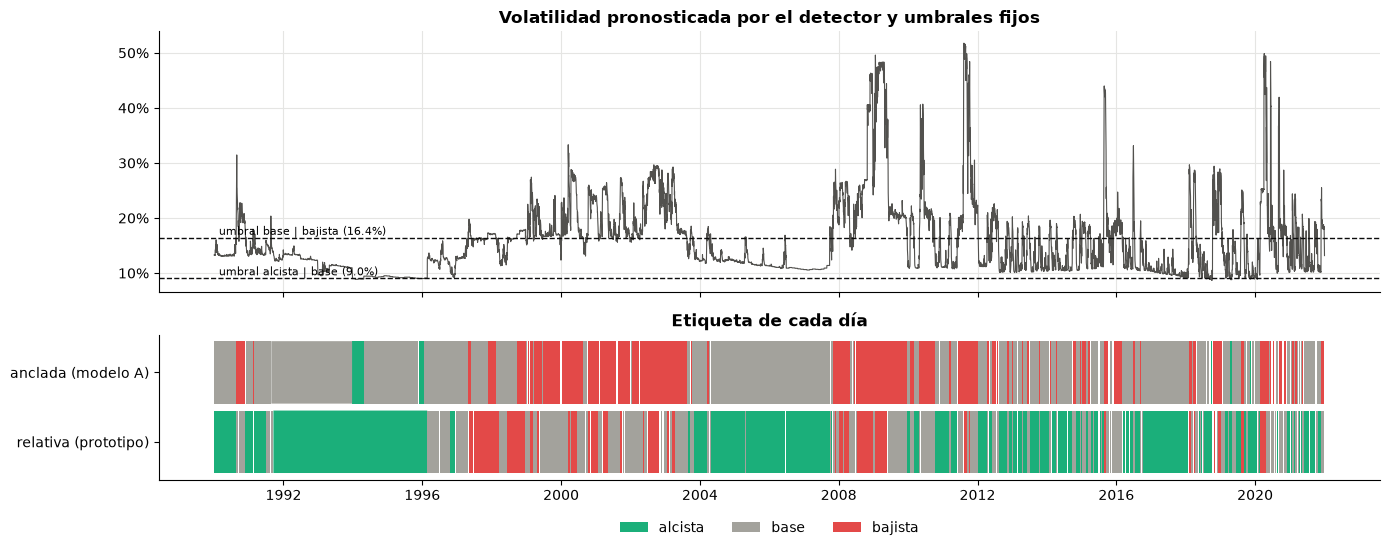

In [10]:
W0 = CONFIG["ventana"]
pr_p = params[PRINCIPAL][:fin].copy()
bajista_viterbi = ruta.values == N - 1
i_re = fechas.get_indexer(pr_p.index)
pr_p["crisis en la ventana"] = [bajista_viterbi[i - W0:i].mean() for i in i_re]
pr_p["tercio"] = pd.qcut(pr_p["crisis en la ventana"].rank(method="first"), 3, labels=["pocas crisis", "intermedia", "muchas crisis"])
tercio_dia = pr_p["tercio"].astype(object).reindex(et_rel.index, method="ffill")
rs_lag = r_simple.shift(-H).reindex(et_rel.index)          # rendimiento que gana la posición decidida ese día


def resumen_etiquetas(et, mascara=None):
    m = slice(None) if mascara is None else mascara
    e, r = et[m], rs_lag[m]
    return {"% días bajista": (e == 2).mean(), "vol. índice en bajista": r[e == 2].std() * np.sqrt(252),
            "vol. índice en base": r[e == 1].std() * np.sqrt(252), "rend. índice en bajista": r[e == 2].mean() * 252}


filas = {}
for t_ in ["pocas crisis", "intermedia", "muchas crisis"]:
    msk = (tercio_dia == t_).values
    filas[(t_, "relativa (prototipo)")] = resumen_etiquetas(et_rel, msk)
    filas[(t_, "anclada (modelo A)")] = resumen_etiquetas(et_anc, msk)
tabla_q1 = pd.DataFrame(filas).T
tabla_q1.index.names = ["ventana", "etiqueta"]

vista = pd.DataFrame({
    ("Volatilidad real del índice en días 'bajistas'", "relativa"): tabla_q1.xs("relativa (prototipo)", level=1)["vol. índice en bajista"],
    ("Volatilidad real del índice en días 'bajistas'", "anclada"): tabla_q1.xs("anclada (modelo A)", level=1)["vol. índice en bajista"],
    ("Días etiquetados como bajistas", "relativa"): tabla_q1.xs("relativa (prototipo)", level=1)["% días bajista"],
    ("Días etiquetados como bajistas", "anclada"): tabla_q1.xs("anclada (modelo A)", level=1)["% días bajista"]})
vista.index.name = "Contenido de la ventana"
print("Tabla Q1.1. ¿Qué tan agitado estaba el mercado en los días que cada etiqueta llamó 'bajistas'? (1990–2021)")
display(vista.style.format("{:.0%}"))

m96 = (et_rel.index >= "1996-01-01") & (et_rel.index <= "1999-12-31")
print(f"Caso 1996–1999 (el índice más que duplicó su valor): días bajistas con la etiqueta relativa {(et_rel[m96] == 2).mean():.0%}, "
      f"con la anclada {(et_anc[m96] == 2).mean():.0%}; volatilidad realizada del índice {r_simple[et_rel.index[m96]].std() * np.sqrt(252):.1%} "
      f"(umbral bajista: {UMBRALES[1]:.1%})")


def por_regimen(et):
    filas = {}
    for i, n in enumerate(NOMBRES):
        r = rs_lag[et == i].dropna()
        ee = r.std() * np.sqrt(252) / np.sqrt(len(r) / 252) if len(r) > 1 else np.nan
        filas[n] = {"Días": (et == i).mean(), "Rendimiento anual del índice": r.mean() * 252,
                    "Intervalo de 95%": f"{r.mean() * 252 - 1.96 * ee:+.1%} a {r.mean() * 252 + 1.96 * ee:+.1%}",
                    "Volatilidad anual del índice": r.std() * np.sqrt(252)}
    return pd.DataFrame(filas).T


print("\nTabla Q1.2. ¿Qué hizo el índice en cada régimen anclado? (compárese con la Tabla IV del Reporte 4)")
display(por_regimen(et_anc).style.format({"Días": "{:.0%}", "Rendimiento anual del índice": "{:+.1%}",
                                          "Volatilidad anual del índice": "{:.1%}"}))

fig, ax = plt.subplots(2, 1, figsize=(14, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.8, 1]})
ax[0].plot(sig, color="#52514e", lw=0.8, label="volatilidad pronosticada")
for u, n in zip(UMBRALES, ["alcista | base", "base | bajista"]):
    ax[0].axhline(u, color="#0b0b0b", ls="--", lw=1)
    ax[0].text(sig.index[5], u, f" umbral {n} ({u:.1%})", va="bottom", fontsize=8)
ax[0].yaxis.set_major_formatter(pct); ax[0].set_title("Volatilidad pronosticada por el detector y umbrales fijos")
for fila, (et, nom) in enumerate([(et_rel, "relativa"), (et_anc, "anclada")]):
    for i, n in enumerate(NOMBRES):
        ax[1].fill_between(et.index, fila, fila + 0.9, where=(et == i).values, color=C_REG[n], lw=0,
                           label=n if fila == 0 else None)
ax[1].set_yticks([0.45, 1.45], ["relativa (prototipo)", "anclada (modelo A)"]); ax[1].grid(False)
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3); ax[1].set_title("Etiqueta de cada día")
plt.tight_layout(); plt.show()


**¿Detecta mejor las crisis?** Se usa la misma referencia del Reporte 4: los 16 episodios bajistas de al menos 20 días que el algoritmo de Viterbi fecha con toda la historia. Un episodio se cuenta como detectado si la regla se pone en posición defensiva dentro del episodio; el retraso son los días hábiles hasta ese momento. Para aislar el efecto de la etiqueta, se compara el prototipo con A0, que usa la misma regla con la etiqueta anclada.


In [11]:
ep_des = episodios[(episodios["inicio"] >= ini) & (episodios["días"] >= CONFIG["dias_min_episodio"])].sort_values("inicio").copy()


def retrasos(w_dec, valor):
    out = []
    for _, e in ep_des.iterrows():
        tramo = (w_dec == valor)[e["inicio"]:e["fin"]]
        out.append(int(np.argmax(tramo.values)) if tramo.any() else np.nan)
    return np.array(out, dtype=float)


ret_rel = retrasos(SENALES["Prototipo (Reporte 4)"], POS[-1])
ret_anc = retrasos(SENALES["A0 anclado con corto"], POS[-1])
print(f"Episodios detectados: etiqueta relativa {np.isfinite(ret_rel).sum()} de {len(ep_des)} (retraso mediano {np.nanmedian(ret_rel):.0f} días) | "
      f"etiqueta anclada {np.isfinite(ret_anc).sum()} de {len(ep_des)} (retraso mediano {np.nanmedian(ret_anc):.0f} días)")
det = pd.DataFrame({"Inicio": ep_des["inicio"].dt.strftime("%Y-%m-%d").values, "Fin": ep_des["fin"].dt.strftime("%Y-%m-%d").values,
                    "Días": ep_des["días"].values, "Rendimiento del índice": ep_des["rend. del índice"].values,
                    "Retraso, etiqueta relativa": ret_rel, "Retraso, etiqueta anclada": ret_anc})
print("Tabla Q1.3. Retraso en días hábiles hasta ponerse a la defensiva en cada episodio")
display(det.style.format({"Rendimiento del índice": "{:+.1%}", "Retraso, etiqueta relativa": "{:.0f}",
                          "Retraso, etiqueta anclada": "{:.0f}"}, na_rep="no detectado").hide(axis="index"))


Episodios detectados: etiqueta relativa 13 de 16 (retraso mediano 5 días) | etiqueta anclada 15 de 16 (retraso mediano 3 días)
Tabla Q1.3. Retraso en días hábiles hasta ponerse a la defensiva en cada episodio


Inicio,Fin,Días,Rendimiento del índice,"Retraso, etiqueta relativa","Retraso, etiqueta anclada"
1990-08-02,1990-10-19,56,-12.1%,no detectado,15
1998-07-21,1998-10-15,62,-11.5%,0,46
2000-01-04,2000-06-02,105,+1.5%,52,5
2000-10-06,2001-01-05,63,-9.6%,7,0
2001-03-09,2001-04-25,33,-2.8%,3,0
2001-09-06,2001-11-01,37,-4.2%,5,0
2002-05-06,2003-04-02,230,-17.9%,4,0
2007-07-24,2007-08-29,27,-5.0%,no detectado,no detectado
2007-11-01,2008-04-01,103,-11.6%,18,2
2008-06-05,2009-07-15,280,-32.3%,25,3


### Lectura de Q1

- **El significado de "bajista" ya es estable.** Con la etiqueta relativa, los días bajistas tenían 29%, 27% o 42% de volatilidad según lo que contuviera la ventana. Con la anclada, 27%, 23% y 27% (Tabla Q1.1). El problema 1 del Reporte 4 queda resuelto en lo que importa: la etiqueta ya no depende de la ventana.
- **El precio de anclar: la escala de 1950–1989 era más tranquila que el mercado de 1990–2021.** El umbral alcista (9.0%) casi nunca se cumple: sólo 2% de los días son alcistas, y 36% son bajistas (Tabla Q1.2). Por eso fue clave invertir también en el régimen base (B.2): con la regla original, el modelo A habría pasado 98% del tiempo en T-bills (Q2).
- **1996–1999 sigue saliendo como bajista (38% de los días), pero ahora por una razón legítima.** Ese mercado subió mucho, pero con 17.3% de volatilidad, por encima del umbral de 16.4%. El detector no se equivoca al decir que el mercado estaba agitado; lo engañoso es el nombre. **"Bajista" debe leerse como "alta volatilidad", no como "a la baja".**
- **La dirección sigue sin anticiparse.** En los días bajistas el índice rindió +11.4% anual, más que en los días base (+9.3%), aunque con un intervalo muy amplio (−3.4% a +26.1%). Es el mismo hallazgo del Reporte 4: el detector mide volatilidad, no dirección.
- **Sí detecta más crisis y más rápido:** 15 de 16 episodios contra 13, con un retraso mediano de 3 días contra 5 (Tabla Q1.3). Ahora reconoce 1990 y 2010, que el prototipo no veía, y en la crisis de 2008–2009 reacciona en 3 días en lugar de 25. Siguen fuera julio–agosto de 2007, un episodio corto, y en 1998 tarda más (46 días contra 0).


## Q2. ¿Qué aporta cada pieza del modelo A?

**Por qué lo preguntamos.** El modelo A combina cuatro cambios respecto al prototipo. Para saber cuál sirve, se agregan uno por uno (una *ablación*):

| Paso | Estrategia | Qué cambia |
|---|---|---|
| 0 | Prototipo (Reporte 4) | Etiqueta relativa; 100% / T-bills / corto de la mitad |
| 1 | A0 | La etiqueta se ancla |
| 2 | A1 | Se quita el corto: en bajista, T-bills |
| 3 | A original (Reporte 4) | Se vuelve al mercado en 1 día en lugar de 3 |
| 4 | **Modelo A** | Se invierte también en el régimen base |

**Qué esperamos.** Que quitar el corto suba el Sharpe, que volver rápido recupere parte de los rebotes después de una crisis y que invertir en base suba el rendimiento sin perder la protección. Todo sin costos, para aislar el efecto de la regla.


Tabla Q2.1. Ablación del modelo A, sin costos, 1990–2021


,"Valor final de $1,000",Rendimiento anual,Volatilidad anual,Sharpe,Caída máxima,Días en el índice,Días en T-bills,Días en corto
Prototipo (Reporte 4),"$2,939",3.4%,10.4%,0.13,-21.9%,53%,32%,15%
A0 anclado con corto,$823,-0.6%,7.7%,-0.37,-57.0%,2%,62%,35%
A1 anclado sin corto,"$2,254",2.6%,1.5%,0.01,-8.9%,2%,98%,0%
A original (Reporte 4),"$2,205",2.5%,1.6%,-0.04,-8.9%,2%,98%,0%
Modelo A,"$5,327",5.4%,10.3%,0.31,-26.9%,67%,33%,0%
Comprar y mantener,"$13,487",8.5%,18.1%,0.40,-56.8%,100%,0%,0%



Tabla Q2.2. Promedio de los 16 episodios de crisis y de los 3 meses siguientes


,Rendimiento durante la crisis,Rendimiento 3 meses después,Crisis en que le gana al índice,Rebotes en que le gana al índice
Prototipo (Reporte 4),-2.8%,+0.5%,56%,25%
A0 anclado con corto,+1.8%,-1.9%,88%,25%
A1 anclado sin corto,+0.7%,+0.6%,100%,25%
A original (Reporte 4),+0.7%,+0.6%,100%,25%
Modelo A,-4.4%,+1.9%,56%,25%
Comprar y mantener,-9.2%,+5.8%,0%,0%


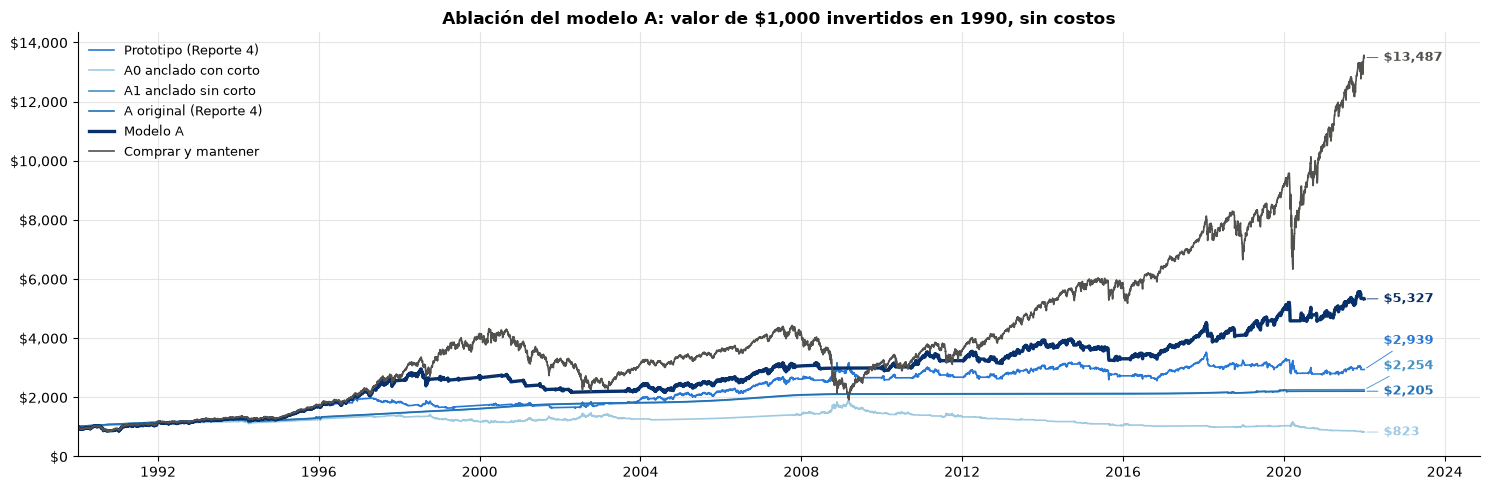

In [12]:
ABLACION = ["Prototipo (Reporte 4)", "A0 anclado con corto", "A1 anclado sin corto", "A original (Reporte 4)", "Modelo A", "Comprar y mantener"]
print("Tabla Q2.1. Ablación del modelo A, sin costos, 1990–2021")
display(tabla(tab["sin costos"].loc[ABLACION], ["valor final", "rend. anual", "vol. anual", "Sharpe", "caída máxima",
                                                "% comprado", "% T-bill", "% corto"], resaltar=["Modelo A"]))

ret_bh = res["sin costos"]["Comprar y mantener"][0]
acum = lambda r, a, b: (1 + r[a:b]).prod() - 1


def rebotes(nombre):
    ret = res["sin costos"][nombre][0]; filas = []
    for _, e in ep_des.iterrows():
        despues = ret.index[ret.index > e["fin"]][:63]
        filas.append({"durante": acum(ret, e["inicio"], e["fin"]), "índice durante": acum(ret_bh, e["inicio"], e["fin"]),
                      "3 meses después": acum(ret, despues[0], despues[-1]),
                      "índice 3 meses después": acum(ret_bh, despues[0], despues[-1])})
    d = pd.DataFrame(filas)
    return {"durante el episodio": d["durante"].mean(), "3 meses después": d["3 meses después"].mean(),
            "gana durante": (d["durante"] > d["índice durante"]).mean(),
            "gana 3 meses después": (d["3 meses después"] > d["índice 3 meses después"]).mean()}


tabla_reb = pd.DataFrame({n: rebotes(n) for n in ABLACION}).T
vista_reb = tabla_reb.rename(columns={"durante el episodio": "Rendimiento durante la crisis", "3 meses después": "Rendimiento 3 meses después",
                                      "gana durante": "Crisis en que le gana al índice", "gana 3 meses después": "Rebotes en que le gana al índice"})
print(f"\nTabla Q2.2. Promedio de los {len(ep_des)} episodios de crisis y de los 3 meses siguientes")
display(vista_reb.style.format("{:+.1%}", subset=vista_reb.columns[:2]).format("{:.0%}", subset=vista_reb.columns[2:]))

fig, ax = plt.subplots(figsize=(15, 5))
grafica_valor(ax, {n: res["sin costos"][n][0] for n in ABLACION},
              "Ablación del modelo A: valor de $1,000 invertidos en 1990, sin costos", resaltar=["Modelo A"])
plt.tight_layout(); plt.show()


### Lectura de Q2

- **Anclar la etiqueta sin cambiar la regla empeora todo (A0).** Con la escala fija, el modelo pasa 35% de los días en corto, en un mercado que en esos días subió. Sharpe de −0.37 y caída de −57%. Confirma que apostar a la baja con este detector no funciona.
- **Quitar el corto elimina las pérdidas, pero deja al modelo casi siempre fuera (A1).** Como sólo 2% de los días son alcistas (Q1), pasa 98% del tiempo en T-bills: rendimiento de 2.6% y Sharpe prácticamente cero.
- **Volver rápido no cambia nada en este punto (A original).** Casi nunca hay a dónde volver: el modelo está fuera del mercado casi todo el tiempo.
- **Invertir en el régimen base es la pieza que hace funcionar al modelo (Modelo A).** Pasa 67% de los días en el índice, sube el Sharpe a 0.31 y el valor final a $5,327, con una caída máxima de −26.9% contra −56.8% del índice. Es la desviación declarada en B.2 antes de ver estos resultados.
- **Los rebotes siguen siendo el punto débil.** En los 3 meses después de una crisis, el modelo A gana +1.9% en promedio contra +5.8% del índice, y le gana sólo en 25% de los episodios (Tabla Q2.2). Mejora respecto al prototipo (+0.5%), pero la volatilidad tarda en bajar del umbral después de una crisis, y para entonces buena parte del rebote ya ocurrió.


## Q3. ¿Cómo se comporta el modelo B?

**Por qué lo preguntamos.** El modelo B se apoya en el argumento de Moreira y Muir [15]: cuando se espera mucha volatilidad, el riesgo sube más que el rendimiento esperado, así que conviene invertir menos en esos días. Cederburg et al. [17] advierten que esta ventaja se debilita mucho fuera de muestra. Por eso primero se verifica la premisa con nuestros datos y después se mira qué hace B.

**Cómo se lee la primera tabla.** Los días se dividen en cinco grupos del mismo tamaño según la volatilidad pronosticada, de los más tranquilos (Q1) a los más agitados (Q5). Si la premisa se cumple, la última columna, el rendimiento por unidad de volatilidad, debería bajar de Q1 a Q5.


Tabla Q3.1. La premisa de Moreira y Muir con nuestros datos (1990–2021)


,Volatilidad pronosticada (mediana),Volatilidad real del índice,Rendimiento anual del índice,Rendimiento / volatilidad
Q1 (calma),9.7%,10.0%,+7.2%,0.72
Q2,11.4%,11.0%,+3.7%,0.34
Q3,13.4%,13.0%,+16.1%,1.24
Q4,17.2%,18.0%,+6.7%,0.37
Q5 (agitado),24.1%,30.4%,+14.9%,0.49



Tabla Q3.2. ¿Cuánto invierte el modelo B?


,Exposición media,Días al 100%,Días por debajo de 50%,Cambios de posición
Modelo B,86%,53%,5%,558
B sin banda,86%,51%,6%,"4,107"



Tabla Q3.3. Desempeño del modelo B, sin costos


,"Valor final de $1,000",Rendimiento anual,Volatilidad anual,Sharpe,Caída máxima
Modelo B,"$9,682",7.4%,13.0%,0.42,-38.5%
B sin banda,"$10,032",7.5%,12.7%,0.43,-37.7%
Comprar y mantener,"$13,487",8.5%,18.1%,0.40,-56.8%


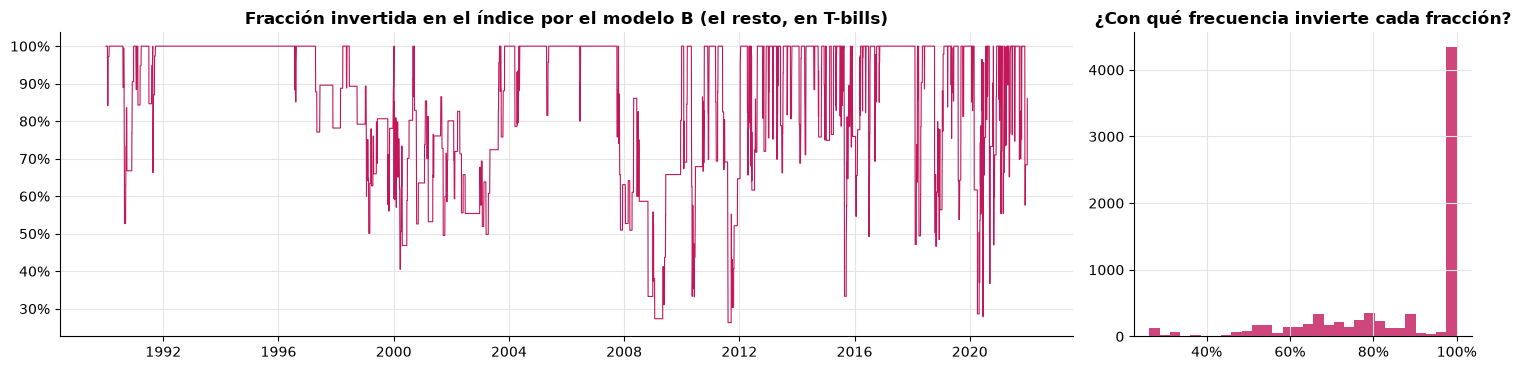

In [13]:
quintil = pd.qcut(sig, 5, labels=["Q1 (calma)", "Q2", "Q3", "Q4", "Q5 (agitado)"])
premisa = pd.DataFrame({q: {"Volatilidad pronosticada (mediana)": sig[quintil == q].median(),
                            "Volatilidad real del índice": rs_lag[quintil == q].std() * np.sqrt(252),
                            "Rendimiento anual del índice": rs_lag[quintil == q].mean() * 252}
                        for q in quintil.cat.categories}).T
premisa["Rendimiento / volatilidad"] = premisa["Rendimiento anual del índice"] / premisa["Volatilidad real del índice"]
print("Tabla Q3.1. La premisa de Moreira y Muir con nuestros datos (1990–2021)")
display(premisa.style.format({"Volatilidad pronosticada (mediana)": "{:.1%}", "Volatilidad real del índice": "{:.1%}",
                              "Rendimiento anual del índice": "{:+.1%}", "Rendimiento / volatilidad": "{:.2f}"}))

wB = res["sin costos"]["Modelo B"][2]
expo = pd.DataFrame({n: {"Exposición media": w.mean(), "Días al 100%": (w >= pB["tope"]).mean(), "Días por debajo de 50%": (w < 0.5).mean(),
                         "Cambios de posición": tab["sin costos"].loc[n, "cambios de posición"]}
                     for n, w in [(k, res["sin costos"][k][2]) for k in ("Modelo B", "B sin banda")]}).T
print("\nTabla Q3.2. ¿Cuánto invierte el modelo B?")
display(expo.style.format({"Exposición media": "{:.0%}", "Días al 100%": "{:.0%}", "Días por debajo de 50%": "{:.0%}",
                           "Cambios de posición": "{:,.0f}"}))
print("\nTabla Q3.3. Desempeño del modelo B, sin costos")
display(tabla(tab["sin costos"].loc[["Modelo B", "B sin banda", "Comprar y mantener"]],
              ["valor final", "rend. anual", "vol. anual", "Sharpe", "caída máxima"], resaltar=["Modelo B"]))

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [3, 1]})
ax[0].plot(wB, color=C_EST["Modelo B"], lw=0.8); ax[0].yaxis.set_major_formatter(pct)
ax[0].set_title("Fracción invertida en el índice por el modelo B (el resto, en T-bills)")
ax[1].hist(wB, bins=30, color=C_EST["Modelo B"], alpha=0.8); ax[1].xaxis.set_major_formatter(pct)
ax[1].set_title("¿Con qué frecuencia invierte cada fracción?")
plt.tight_layout(); plt.show()


### Lectura de Q3

- **La premisa se cumple sólo a medias.** La volatilidad real sube con orden, de 10% en los días más tranquilos a 30% en los más agitados, así que el detector **sí pronostica bien la volatilidad**. Pero el rendimiento no baja con orden (+7.2%, +3.7%, +16.1%, +6.7% y +14.9%), y el rendimiento por unidad de volatilidad tampoco (Tabla Q3.1). Es lo que advierten Cederburg et al. [17]: en una muestra concreta, la ventaja de reducir la exposición cuando hay mucha volatilidad es débil. Además, en los días más agitados el pronóstico se queda corto (24% pronosticado contra 30% real): las crisis más fuertes llegan más rápido de lo que el modelo anticipa.
- **El modelo B casi siempre está muy invertido.** Su exposición promedio es de 86%: la mitad de los días está al 100% y sólo 5% de los días invierte menos de la mitad (Tabla Q3.2). En la práctica, es comprar y mantener con recortes en los periodos agitados.
- **Aun así, consigue lo que buscábamos.** Su Sharpe es de 0.42 contra 0.40 del índice, con 13.0% de volatilidad en lugar de 18.1% y una caída máxima de −38.5% en lugar de −56.8% (Tabla Q3.3). Termina con menos dinero ($9,682 contra $13,487) porque está menos invertido, no porque invierta peor.
- **La banda funciona.** El rendimiento es casi el mismo que rebalanceando a diario (Sharpe 0.42 contra 0.43), con 558 cambios de posición en lugar de 4,107. Esto importa con costos (Q4).


## Q4. ¿Sobreviven los costos de transacción?

**Por qué lo preguntamos.** Hasta el Reporte 4 no descontábamos costos. Cada vez que una estrategia cambia de posición paga una comisión; aquí se cobra 0.1% por cada unidad que cambia la fracción invertida, como en Bulla et al. [9]. La *rotación anual* mide cuánto cambia la posición en un año: 1.0 equivale a sacar todo el dinero del índice una vez y volver a meterlo una vez.

**Qué esperamos.** Que los costos castiguen en proporción a la rotación: poco a los modelos A y B, y mucho a la cadena de Markov (834 cambios de posición en el Reporte 4).


Tabla Q4.1. Efecto de un costo de 0.1% por unidad de cambio en la posición, 1990–2021


,Rotación anual,Costo anual,Sharpe sin costos,Sharpe con costos,Valor final sin costos,Valor final con costos,Caída máxima con costos
Prototipo (Reporte 4),4.7,0.49%,0.13,0.09,"$2,939","$2,527",-24.5%
Modelo A,5.1,0.53%,0.31,0.26,"$5,327","$4,531",-30.1%
Modelo B,2.4,0.26%,0.42,0.40,"$9,682","$8,965",-38.9%
B sin banda,4.5,0.49%,0.43,0.39,"$10,032","$8,677",-38.7%
Comprar y mantener,0.0,0.00%,0.40,0.40,"$13,487","$13,487",-56.8%
Markov observable 1er orden,26.1,2.81%,0.46,0.31,"$17,174","$7,456",-60.2%



Tabla Q4.2. Desempeño completo con costos (la versión realista)


,"Valor final de $1,000",Rendimiento anual,Volatilidad anual,Sharpe,Caída máxima,Cambios de posición
Prototipo (Reporte 4),"$2,527",2.9%,10.4%,0.09,-24.5%,177
Modelo A,"$4,531",4.8%,10.3%,0.26,-30.1%,162
Modelo B,"$8,965",7.1%,13.0%,0.40,-38.9%,558
B sin banda,"$8,677",7.0%,12.7%,0.39,-38.7%,4107
Comprar y mantener,"$13,487",8.5%,18.1%,0.40,-56.8%,0
Markov observable 1er orden,"$7,456",6.5%,16.7%,0.31,-60.2%,834


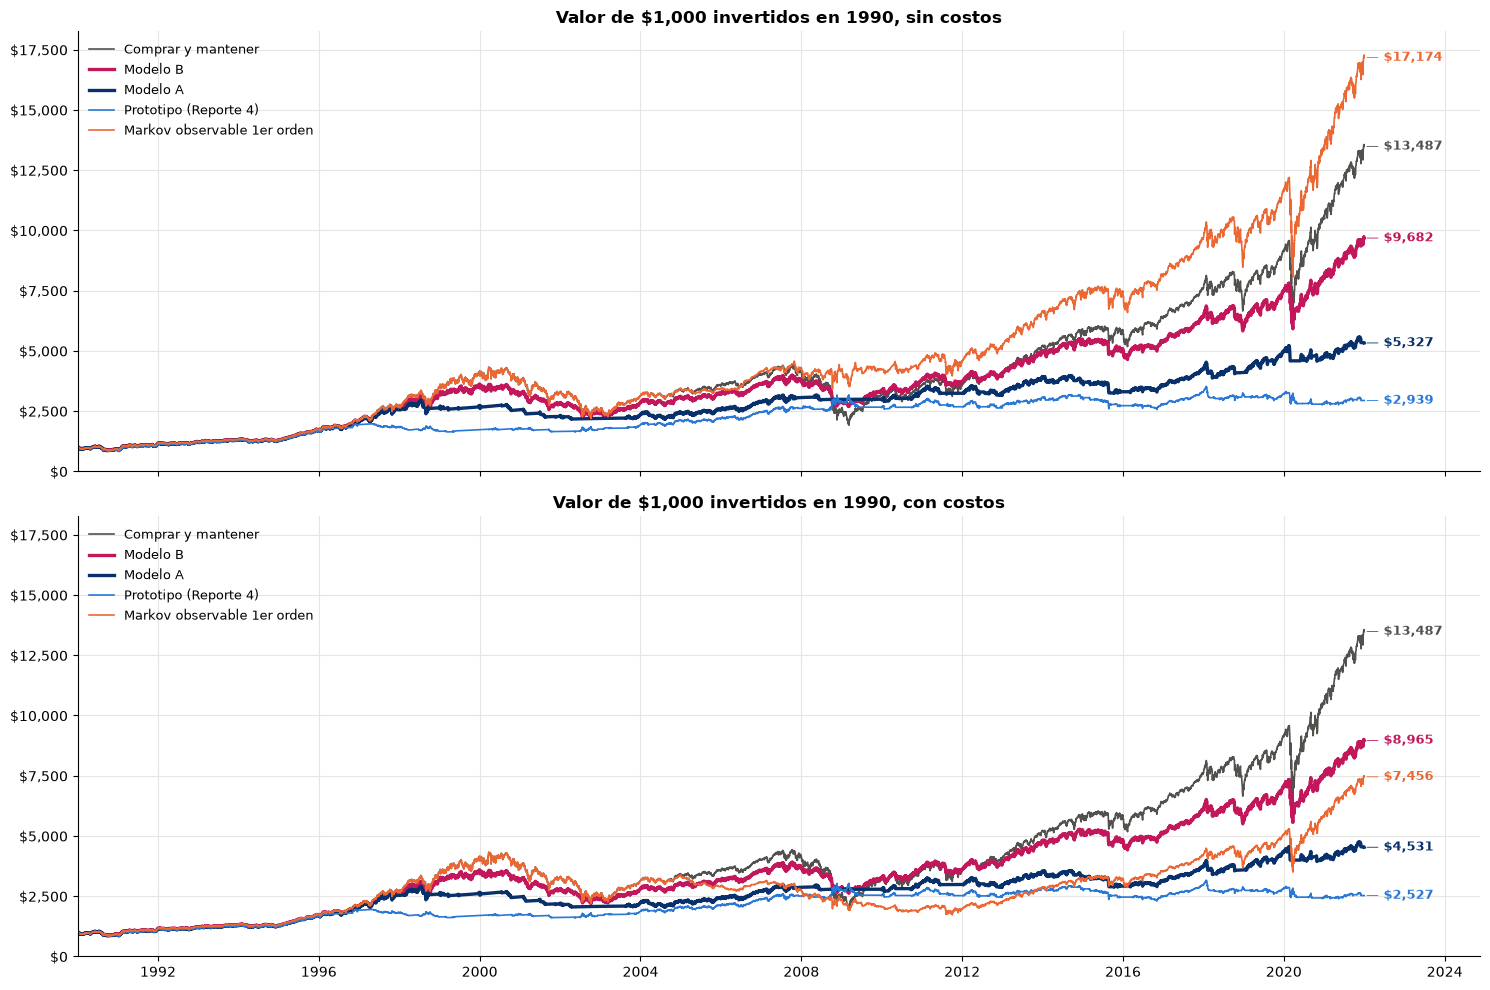

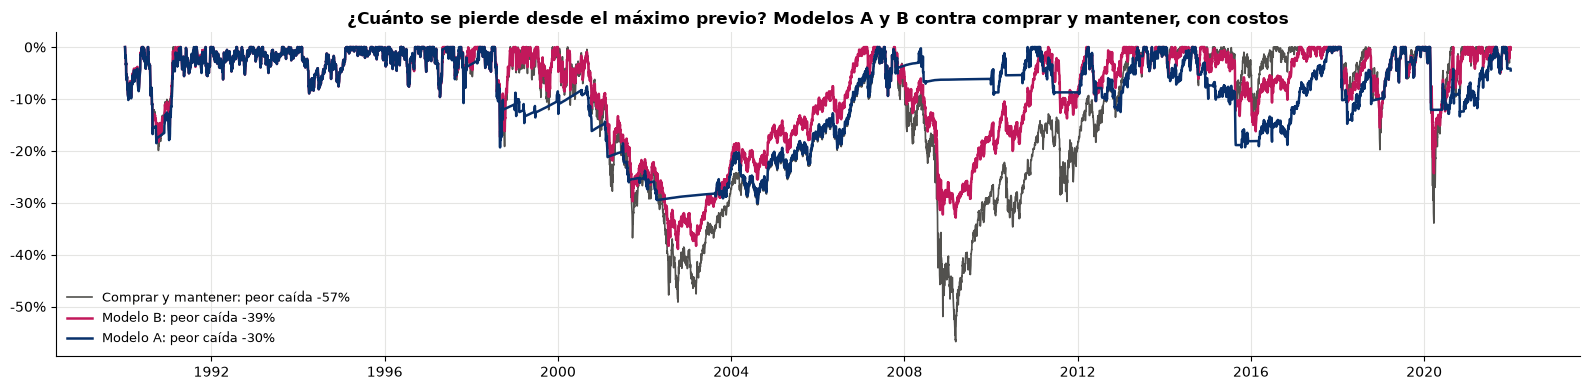

Tabla Q4.3. Peor caída desde el máximo previo en cada crisis, con costos


,Comprar y mantener,Modelo B,Modelo A
Burbuja tecnológica (2000–2003),-49.1%,-38.9%,-29.5%
Crisis financiera (2007–2009),-56.8%,-32.9%,-9.4%
COVID (2020),-33.9%,-24.3%,-13.4%


In [14]:
REPORTADAS = ["Prototipo (Reporte 4)", "Modelo A", "Modelo B", "B sin banda", "Comprar y mantener", "Markov observable 1er orden"]
q4 = pd.DataFrame({
    "Rotación anual": tab["sin costos"].loc[REPORTADAS, "rotación anual"],
    "Costo anual": tab["sin costos"].loc[REPORTADAS, "rend. anual"] - tab["con costos"].loc[REPORTADAS, "rend. anual"],
    "Sharpe sin costos": tab["sin costos"].loc[REPORTADAS, "Sharpe"], "Sharpe con costos": tab["con costos"].loc[REPORTADAS, "Sharpe"],
    "Valor final sin costos": tab["sin costos"].loc[REPORTADAS, "valor final"],
    "Valor final con costos": tab["con costos"].loc[REPORTADAS, "valor final"],
    "Caída máxima con costos": tab["con costos"].loc[REPORTADAS, "caída máxima"]})
print(f"Tabla Q4.1. Efecto de un costo de {COSTO:.1%} por unidad de cambio en la posición, 1990–2021")
display(q4.style.format({"Rotación anual": "{:.1f}", "Costo anual": "{:.2%}", "Sharpe sin costos": "{:.2f}", "Sharpe con costos": "{:.2f}",
                         "Valor final sin costos": "${:,.0f}", "Valor final con costos": "${:,.0f}", "Caída máxima con costos": "{:.1%}"}))
print("\nTabla Q4.2. Desempeño completo con costos (la versión realista)")
display(tabla(tab["con costos"].loc[REPORTADAS], ["valor final", "rend. anual", "vol. anual", "Sharpe", "caída máxima", "cambios de posición"],
              resaltar=["Modelo A", "Modelo B"]))

GRAF = ["Comprar y mantener", "Modelo B", "Modelo A", "Prototipo (Reporte 4)", "Markov observable 1er orden"]
fig, ax = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
for a, c in zip(ax, ["sin costos", "con costos"]):
    grafica_valor(a, {n: res[c][n][0] for n in GRAF}, f"Valor de $1,000 invertidos en 1990, {c}", resaltar=["Modelo A", "Modelo B"])
ymax = max(a.get_ylim()[1] for a in ax)
for a in ax: a.set_ylim(0, ymax)                       # misma escala en los dos paneles para poder compararlos
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(16, 4))
for n in ["Comprar y mantener", "Modelo B", "Modelo A"]:
    riqueza = INICIAL * (1 + res["con costos"][n][0]).cumprod()
    caida = riqueza / riqueza.cummax() - 1
    ax.plot(caida, color=C_EST[n], lw=1.8 if n != "Comprar y mantener" else 1.2, label=f"{n}: peor caída {caida.min():.0%}")
ax.yaxis.set_major_formatter(pct); ax.legend(loc="lower left", fontsize=9)
ax.set_title("¿Cuánto se pierde desde el máximo previo? Modelos A y B contra comprar y mantener, con costos")
plt.tight_layout(); plt.show()

CRISIS = {"Burbuja tecnológica (2000–2003)": ("2000-01-01", "2003-12-31"), "Crisis financiera (2007–2009)": ("2007-07-01", "2009-12-31"),
          "COVID (2020)": ("2020-01-01", "2020-12-31")}
caidas = {}
for n in ["Comprar y mantener", "Modelo B", "Modelo A"]:
    riqueza = INICIAL * (1 + res["con costos"][n][0]).cumprod()
    dd = riqueza / riqueza.cummax() - 1
    caidas[n] = {k: dd[a:b].min() for k, (a, b) in CRISIS.items()}
print("Tabla Q4.3. Peor caída desde el máximo previo en cada crisis, con costos")
display(pd.DataFrame(caidas).style.format("{:.1%}"))


### Lectura de Q4

- **Los costos acaban con la cadena de Markov.** Sin costos era la única estrategia que superaba al índice (Sharpe 0.46 y $17,174), pero cambia de posición unas 26 veces al año y paga 2.8% anual en comisiones. Con costos su Sharpe cae a 0.31, termina con $7,456 y su caída máxima empeora a −60% (Tabla Q4.1). Se confirma lo que sospechábamos en el Reporte 4.
- **El modelo B es el más resistente.** Paga 0.26% al año y su Sharpe apenas pasa de 0.42 a 0.40, igual al del índice. El modelo A paga 0.53% al año y baja de 0.31 a 0.26.
- **La banda de B se paga sola.** Rebalanceando a diario, B ganaba un poco más sin costos, pero con costos termina por debajo de la versión con banda ($8,677 contra $8,965).
- **En las caídas está el valor de los modelos (Tabla Q4.3).** En la crisis financiera de 2008–2009, rápida y muy volátil, el índice llegó a perder 57% desde su máximo; el modelo B, alrededor de un tercio, y el modelo A mucho menos, porque salió a tiempo (Q1). En la burbuja tecnológica de 2000–2003, una caída lenta con volatilidad moderada, la protección es menor: ahí ocurren las peores caídas de los dos modelos (−39% B y −30% A). El detector protege mejor contra las crisis violentas que contra las lentas.
- **Cómo leer las gráficas de valor.** Los tramos casi planos del modelo A (por ejemplo, 2002–2003 y 2008–2010) son periodos en T-bills: no pierde, pero tampoco participa en la recuperación, que es justo el problema de los rebotes de Q2.


## Q5. ¿Cuál es mejor, y podría ser suerte?

### Comparación pareada del Sharpe (Ledoit y Wolf [16])

**Por qué.** Dos estrategias que invierten en el mismo índice suben y bajan juntas. Si se compara el Sharpe de cada una por separado, ese ruido común hace que casi cualquier diferencia parezca insignificante: en el Reporte 4 no se distinguían diferencias menores a 0.36. La prueba pareada compara las dos estrategias **día por día**. El movimiento común del mercado se cancela y queda sólo lo que las distingue, como al comparar a dos corredores en la misma carrera, con el mismo viento.

**Cómo funciona.** Para la diferencia $\Delta = SR_1 - SR_2$, el método delta da su error estándar

$$\widehat{\mathrm{EE}}(\hat\Delta) = \sqrt{\nabla f(\hat v)^\top\, \hat\Psi\, \nabla f(\hat v)\,/\,T}$$

donde $v$ son las medias y los segundos momentos de los excesos de las dos estrategias y $\hat\Psi$ es su covarianza de largo plazo, robusta a heterocedasticidad y autocorrelación (núcleo de Bartlett con $L = \lfloor 4 (T/100)^{2/9} \rfloor$ rezagos, una simplificación del núcleo que proponen Ledoit y Wolf).

**Cómo se lee la tabla.** Un p-valor menor a 0.05 significa que la diferencia es estadísticamente distinta de cero. La última columna muestra el error estándar que tendríamos sin parear, para ver cuánta precisión se gana.


In [15]:
def ledoit_wolf(ex1, ex2):
    r = np.column_stack([ex1.values, ex2.values]); T = len(r)
    mu, g = r.mean(0), (r ** 2).mean(0)
    y = np.column_stack([r - mu, r ** 2 - g])
    L = int(np.floor(4 * (T / 100) ** (2 / 9)))
    Psi = y.T @ y / T
    for l in range(1, L + 1):
        G = y[l:].T @ y[:-l] / T
        Psi += (1 - l / (L + 1)) * (G + G.T)
    a, b = mu; c, d = g
    sr1, sr2 = a / np.sqrt(c - a ** 2), b / np.sqrt(d - b ** 2)
    grad = np.array([c / (c - a ** 2) ** 1.5, -d / (d - b ** 2) ** 1.5, -a / (2 * (c - a ** 2) ** 1.5), b / (2 * (d - b ** 2) ** 1.5)])
    ee = np.sqrt(grad @ Psi @ grad / T)
    z = (sr1 - sr2) / ee
    return {"Sharpe 1": sr1 * np.sqrt(252), "Sharpe 2": sr2 * np.sqrt(252), "diferencia": (sr1 - sr2) * np.sqrt(252),
            "EE pareado": ee * np.sqrt(252), "p-valor": 2 * (1 - stats.norm.cdf(abs(z))),
            "correlación": np.corrcoef(r.T)[0, 1], "EE sin parear": np.sqrt(ee_sharpe(ex1) ** 2 + ee_sharpe(ex2) ** 2)}


PARES = [("Modelo A", "Modelo B"), ("Modelo A", "Comprar y mantener"), ("Modelo B", "Comprar y mantener"),
         ("Modelo A", "Prototipo (Reporte 4)"), ("Modelo B", "Prototipo (Reporte 4)")]
tabla_lw = pd.DataFrame({(c, f"{a} − {b}"): ledoit_wolf(res[c][a][1], res[c][b][1]) for c in res for a, b in PARES}).T
tabla_lw.index.names = ["costos", "comparación"]
vista_lw = tabla_lw.rename(columns={"Sharpe 1": "Sharpe de la primera", "Sharpe 2": "Sharpe de la segunda", "diferencia": "Diferencia",
                                    "EE pareado": "Error estándar pareado", "p-valor": "p-valor", "correlación": "Correlación diaria",
                                    "EE sin parear": "Error estándar sin parear"})
print("Tabla Q5.1. Diferencias de Sharpe con la prueba pareada")
display(vista_lw.style.format({"Sharpe de la primera": "{:.2f}", "Sharpe de la segunda": "{:.2f}", "Diferencia": "{:+.2f}",
                               "Error estándar pareado": "{:.2f}", "p-valor": "{:.2f}", "Correlación diaria": "{:.2f}",
                               "Error estándar sin parear": "{:.2f}"}))


Tabla Q5.1. Diferencias de Sharpe con la prueba pareada


### Sharpe tradicional, probabilístico y deflactado

**Por qué.** Probamos 50 variantes a lo largo del proyecto (44 en el Reporte 4 y 6 aquí). Si se prueban muchas, alguna sale bien por pura suerte [6]. Por eso, para cada estrategia se reportan tres medidas en el mismo renglón:

- **Sharpe tradicional:** el rendimiento sobre los T-bills por unidad de volatilidad, tal cual.
- **PSR (aislado):** la probabilidad de que el Sharpe verdadero sea mayor que cero *si esta estrategia fuera la única que probamos*.
- **DSR (bitácora):** la misma probabilidad, pero exigiendo superar el Sharpe $SR_0$ que alcanzaría por suerte la mejor de las 50 pruebas [14]. El criterio usual es que pase de 0.95.

La distancia entre el PSR y el DSR es el costo de haber probado muchas variantes. Se calcula con dos bitácoras completas: todas las pruebas sin costos y todas con costos. "Lugar" es la posición de cada estrategia por Sharpe entre las 50 pruebas.


Bitácora sin costos: M = 50 pruebas, correlación media 0.58, 21.6 pruebas efectivas, umbral SR0 = 0.30 anual
Bitácora con costos: M = 50 pruebas, correlación media 0.58, 21.7 pruebas efectivas, umbral SR0 = 0.33 anual
Comprar y mantener no está en la bitácora (no es una prueba nuestra): su DSR se muestra sólo como referencia.
Tabla Q5.2. Sharpe tradicional, PSR y DSR de cada estrategia


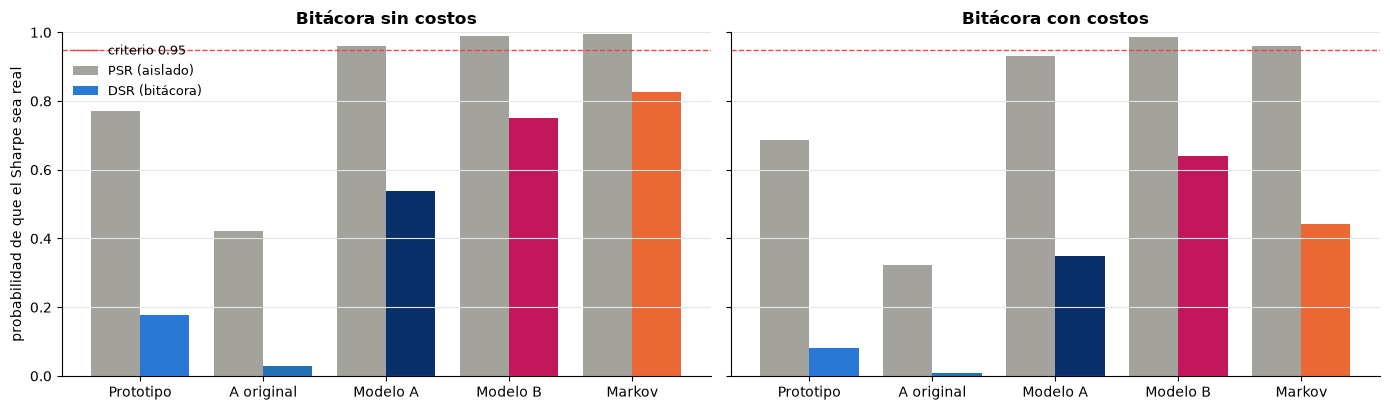

In [16]:
nuevas = list(SENALES_NUEVAS)
EX = {"sin costos": pd.concat([ex_v5_sc, pd.DataFrame({n: res["sin costos"][n][1] for n in nuevas})], axis=1),
      "con costos": pd.concat([ex_v5_cc, pd.DataFrame({n: res["con costos"][n][1] for n in nuevas})], axis=1)}
ALIAS = {"Prototipo (Reporte 4)": V5["principal_bitacora"], "Markov observable 1er orden": "Markov observable 1er orden"}
assert EX["sin costos"].shape[1] == 50 and EX["con costos"].shape[1] == 50

filas = {}
for c in EX:
    srs = EX[c].mean() / EX[c].std()
    for n in ["Prototipo (Reporte 4)", "A0 anclado con corto", "A1 anclado sin corto", "A original (Reporte 4)", "Modelo A",
              "Modelo B", "B sin banda",
              "Markov observable 1er orden", "Comprar y mantener"]:
        ex = res[c][n][1]
        d = sharpe_deflactado(ex, EX[c])
        col = ALIAS.get(n, n)
        filas[(c, n)] = {"Sharpe": d["Sharpe anual"], "EE Sharpe": ee_sharpe(ex), "PSR (aislado)": d["PSR (Sharpe > 0)"],
                         "DSR (bitácora)": d["DSR"], "pasa 0.95": d["DSR"] > 0.95,
                         "lugar": int((srs > ex.mean() / ex.std() + 1e-12).sum()) + 1 if col in EX[c] else np.nan}
    info = sharpe_deflactado(EX[c].iloc[:, 0], EX[c])
    print(f"Bitácora {c}: M = {info['pruebas (M)']} pruebas, correlación media {info['correlación media']:.2f}, "
          f"{info['pruebas efectivas']:.1f} pruebas efectivas, umbral SR0 = {info['umbral SR0 diario'] * np.sqrt(252):.2f} anual")
tabla_q5 = pd.DataFrame(filas).T
tabla_q5.index.names = ["costos", "estrategia"]
print("Comprar y mantener no está en la bitácora (no es una prueba nuestra): su DSR se muestra sólo como referencia.")
vista_q5 = tabla_q5.drop(columns=["EE Sharpe"]).rename(columns={"pasa 0.95": "¿Pasa 0.95?", "lugar": "Lugar (de 50)"})
vista_q5["¿Pasa 0.95?"] = vista_q5["¿Pasa 0.95?"].map({True: "sí", False: "no"})
print("Tabla Q5.2. Sharpe tradicional, PSR y DSR de cada estrategia")
display(vista_q5.style.format({"Sharpe": "{:.2f}", "PSR (aislado)": "{:.2f}", "DSR (bitácora)": "{:.2f}", "Lugar (de 50)": "{:.0f}"},
                              na_rep="—"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for a, c in zip(ax, EX):
    t = tabla_q5.loc[c]
    orden = ["Prototipo (Reporte 4)", "A original (Reporte 4)", "Modelo A", "Modelo B", "Markov observable 1er orden"]
    xs = np.arange(len(orden))
    a.bar(xs - 0.2, t.loc[orden, "PSR (aislado)"].astype(float), 0.4, color="#a3a29c", label="PSR (aislado)")
    a.bar(xs + 0.2, t.loc[orden, "DSR (bitácora)"].astype(float), 0.4, color=[C_EST[n] for n in orden], label="DSR (bitácora)")
    a.axhline(0.95, color="#e34948", ls="--", lw=1, label="criterio 0.95")
    a.set_xticks(xs, ["Prototipo", "A original", "Modelo A", "Modelo B", "Markov"]); a.set_title(f"Bitácora {c}")
    a.set_ylim(0, 1); a.grid(axis="x", visible=False)
ax[0].legend(fontsize=9); ax[0].set_ylabel("probabilidad de que el Sharpe sea real")
plt.tight_layout(); plt.show()


### Lectura de Q5

- **El modelo B y el índice tienen, con mucha precisión, el mismo Sharpe.** La diferencia es de +0.02 sin costos y de 0.00 con costos (p-valor de 0.74 y 0.97). Gracias a la prueba pareada, el error estándar es de 0.05 en lugar de 0.25 sin parear: cinco veces más preciso. No es que no se pueda distinguir por falta de datos; es que son iguales. Que B lo logre con 28% menos volatilidad es el resultado central.
- **A contra B: B es mejor en los números, pero no con significancia.** La diferencia es de −0.13 con costos, con p-valor de 0.26.
- **Los dos mejoran mucho al prototipo**, aunque tampoco con significancia al 5%: +0.18 el modelo A (p = 0.20) y +0.31 el modelo B (p = 0.11), con costos.
- **Ninguna estrategia pasa el filtro de la suerte.** Vistas de forma aislada, B (PSR de 0.99) y A (0.93) parecen sólidas. Descontando las 50 pruebas, el DSR baja a 0.64 y 0.35 con costos. B es la estrategia nuestra mejor ubicada (lugar 3 de 50 con costos), pero no llega a 0.95.
- **Para dimensionarlo:** ni siquiera comprar y mantener pasaría el filtro (DSR de 0.65). Con 32 años de datos y Sharpe cercanos a 0.4, ninguna estrategia de este tipo puede descartar la suerte con ese criterio. Lo que sí podemos afirmar es más modesto, y sólido: **B iguala al índice en rendimiento por unidad de riesgo y reduce el riesgo.**


# D. Conclusiones, regla congelada y tramo reservado
## D.1 Conclusiones

La tabla resume la versión realista (con costos) y el Sharpe deflactado de cada estrategia.


In [17]:
FINALES = ["Comprar y mantener", "Modelo B", "Modelo A", "Prototipo (Reporte 4)", "Markov observable 1er orden"]
cc = tab["con costos"]
resumen = cc.loc[FINALES, ["valor final", "rend. anual", "vol. anual", "Sharpe", "caída máxima"]].rename(columns=ETIQ)
resumen["DSR"] = tabla_q5.loc["con costos"].loc[FINALES, "DSR (bitácora)"].astype(float)
print("Tabla D.1. Resumen final, con costos, 1990–2021")
display(resumen.style.format({ETIQ["valor final"]: "${:,.0f}", ETIQ["rend. anual"]: "{:.1%}", ETIQ["vol. anual"]: "{:.1%}",
                              "Sharpe": "{:.2f}", ETIQ["caída máxima"]: "{:.1%}", "DSR": "{:.2f}"}).apply(
    lambda r: ["font-weight: bold" if r.name in ("Modelo A", "Modelo B") else "" for _ in r], axis=1))


Tabla D.1. Resumen final, con costos, 1990–2021


,"Valor final de $1,000",Rendimiento anual,Volatilidad anual,Sharpe,Caída máxima,DSR
Comprar y mantener,"$13,487",8.5%,18.1%,0.40,-56.8%,0.65
Modelo B,"$8,965",7.1%,13.0%,0.40,-38.9%,0.64
Modelo A,"$4,531",4.8%,10.3%,0.26,-30.1%,0.35
Prototipo (Reporte 4),"$2,527",2.9%,10.4%,0.09,-24.5%,0.08
Markov observable 1er orden,"$7,456",6.5%,16.7%,0.31,-60.2%,0.44


**1. El detector sirve para medir el riesgo, no para pronosticar la dirección.** Pronostica bien la volatilidad (Q3) y, con etiquetas ancladas, detecta 15 de 16 crisis con 3 días de retraso mediano (Q1). Pero en los días que llama bajistas el índice no rindió menos (Q1), y ponerse en corto restó en todos los casos (A0 y prototipo, Q2).

**2. La forma gradual de usarlo (B) funciona mejor que la de escalón (A).** B recorta la exposición sólo en la medida en que sube la volatilidad, y casi nunca sale del todo. A sale por completo y tarda en volver, así que se pierde los rebotes (+1.9% contra +5.8% del índice en los 3 meses siguientes a una crisis).

**3. El modelo B cumple el objetivo de producto: reducir el riesgo sin sacrificar el rendimiento ajustado por riesgo.** Con costos, su Sharpe es igual al del índice (0.40 contra 0.40, p = 0.97), con 13.0% de volatilidad contra 18.1% y una caída máxima de −38.9% contra −56.8%. Los costos casi no lo afectan.

**4. Ninguna estrategia le gana al índice en Sharpe, ni descarta la suerte.** Ningún DSR pasa de 0.95. No podemos afirmar que el detector mejore el rendimiento ajustado por riesgo, y no lo afirmamos.

**5. Los cinco problemas del Reporte 4:**

| # | Problema | Estado | Evidencia |
|---|---|---|---|
| 1 | Etiquetas relativas a la ventana | Resuelto, con un costo | La volatilidad de los días bajistas ya no depende de la ventana (27%, 23% y 27%), pero la escala de 1950–1989 resultó tranquila para 1990–2021: sólo 2% de los días son alcistas |
| 2 | Volatilidad traducida en dirección | Resuelto | Sin corto; B ajusta la exposición en lugar de apostar a la dirección |
| 3 | Sale tarde de la defensa | Mejora parcial | +1.9% contra +0.5% del prototipo en los rebotes, todavía lejos del +5.8% del índice |
| 4 | Poco poder para comparar el Sharpe | Resuelto | Error estándar pareado de 0.05 a 0.19 según el par, contra 0.25 sin parear |
| 5 | Rendimientos sin costos | Resuelto | Todo se reporta sin y con costos; la cadena de Markov pierde su ventaja |

**Qué sigue.** Los modelos A y B, congelados en D.2, se evalúan una sola vez en el tramo reservado (2022 – septiembre 2026) en el Reporte 6.


## D.2 Regla congelada

A partir de aquí no se cambia nada. La huella de la regla resume la configuración heredada, las decisiones de los modelos A y B (incluida la desviación de B.2) y los umbrales anclados; en el Reporte 6 debe imprimirse la misma antes de abrir el tramo reservado.


In [18]:
REGLA_FINAL = {"CONFIG": CONFIG, "MODELOS": MODELOS, "UMBRALES": [round(float(u), 6) for u in UMBRALES],
               "modelo": f"HMM {DIST}, N = {N}", "huella_datos": huella}
huella_regla = hashlib.md5(json.dumps(REGLA_FINAL, sort_keys=True, default=str).encode()).hexdigest()[:10]
print(f"Huella de la regla congelada: {huella_regla}")
print(json.dumps({k: REGLA_FINAL[k] for k in ("MODELOS", "UMBRALES", "modelo")}, indent=1, ensure_ascii=False, default=str))


Huella de la regla congelada: 897fd3d539
{
 "MODELOS": {
  "inversion_inicial": 1000,
  "costo": 0.001,
  "horizonte": 2,
  "umbrales": "media geométrica de las volatilidades de regímenes vecinos del modelo de 1950–1989",
  "A": {
   "posicion": {
    "alcista": 1.0,
    "base": 1.0,
    "bajista": 0.0
   },
   "dias_salir": 3,
   "dias_volver": 1
  },
  "A_original": {
   "posicion": {
    "alcista": 1.0,
    "base": 0.0,
    "bajista": 0.0
   }
  },
  "B": {
   "vol_objetivo": 0.135,
   "tope": 1.0,
   "banda": 0.1
  }
 },
 "UMBRALES": [
  0.090433,
  0.163969
 ],
 "modelo": "HMM t, N = 3"
}


# E. Examen final: el tramo reservado (2022 – septiembre 2026)

**Qué es.** La única evaluación de los modelos A y B con datos que nunca se usaron para decidir nada [6]. El detector se extiende al tramo reservado con la misma estimación móvil (ventana de 2,000 días, reestimación mensual, sólo datos anteriores a cada día), **sin cortes**: la cadena de reestimaciones que empezó en 1990 sigue en 2022 como la habría seguido un inversionista en tiempo real.

**Desviación declarada respecto al Reporte 5 (21 de noviembre de 2026, antes de abrir el tramo).** La celda D.3 del v6.1 reiniciaba el detector el 3 de enero de 2022 con inicializaciones aleatorias. No era una decisión de diseño: el v5.1 no guardaba el último modelo de 2021. Aquí se corrige: se vuelve a correr la cadena completa desde 1990 con el mismo código y la misma semilla (2026). La celda E.1 verifica que la parte de 1990–2021 sea **idéntica** a la del v5.1; si no lo es, el notebook se detiene. Así, en el tramo reservado sólo se agregan días. La regla congelada no cambia (su huella no incluye el arranque) y los cinco índices del notebook 03 quedan con el mismo protocolo.

**Qué no cambia.** Datos, modelo, reglas, umbrales (9.0% y 16.4%), volatilidad objetivo (13.5%), banda de 10 puntos, costo de 0.1% por unidad de |Δw| y rezago de ejecución. La celda siguiente verifica que la huella de la regla sea la del Reporte 5.

## E.0 Hipótesis declaradas antes de abrir el tramo

Salen de lo que encontramos en el desarrollo (Reporte 5). Se evalúan **con costos**, que es la versión realista.

| | Hipótesis | Criterio | De dónde sale |
|---|---|---|---|
| H1 | B reduce el riesgo | Volatilidad anual **y** caída máxima de B menores que las del índice | Q3 y Q4: −28% de volatilidad, caída de −39% contra −57% |
| H2 | B no sacrifica rendimiento ajustado por riesgo | La diferencia de Sharpe B − índice **no** es negativa con p < 0.05 (Ledoit y Wolf) | Q5: diferencia 0.00, p = 0.97 |
| H3 | A reduce el riesgo | Volatilidad anual **y** caída máxima de A menores que las del índice | Q2 y Q4 |
| H4 | A se pierde los rebotes | En la mayoría de los episodios de caída, A rinde menos que el índice en los 63 días hábiles siguientes al mínimo | Q2: +1.9% contra +5.8% |
| H5 | Los modelos protegen más en las caídas rápidas | La protección de A y la de B son mayores en el episodio más rápido que en el más lento | Q4: 2008 contra 2000–2003 |
| H6 | B es al menos tan bueno como A | Sharpe de B ≥ Sharpe de A | Q5: diferencia de −0.13 a favor de B |

**Episodio de caída:** un tramo en que el índice cae al menos 10% desde su máximo previo dentro del tramo reservado; va del máximo hasta que el índice lo recupera. **Velocidad:** caída del índice entre los días hábiles que tarda en llegar del máximo al mínimo. **Protección:** 1 − (caída de la estrategia / caída del índice) entre el máximo y el mínimo.

**Qué esperamos del Sharpe deflactado.** Con unos 1,190 días y un Sharpe cercano a 0.4, el PSR y el DSR difícilmente pasarán de 0.95 aunque los modelos funcionen como en el desarrollo. Lo declaramos antes de verlo: la evidencia fuerte del tramo reservado son las medidas de riesgo y la prueba pareada, no el DSR.

In [19]:
import os
assert EVALUAR_RESERVADO, "La sección E sólo corre con EVALUAR_RESERVADO = True"
HUELLA_REPORTE_5 = "897fd3d539"
assert huella_regla == HUELLA_REPORTE_5, (f"La regla cambió ({huella_regla} ≠ {HUELLA_REPORTE_5}): "
                                          "el tramo reservado ya no sería un examen limpio")

HIPOTESIS = {
    "H1": "B reduce el riesgo: volatilidad anual y caída máxima menores que las del índice (con costos)",
    "H2": "B no sacrifica Sharpe: la diferencia B − índice no es negativa con p menor que 0.05 (Ledoit y Wolf, con costos)",
    "H3": "A reduce el riesgo: volatilidad anual y caída máxima menores que las del índice (con costos)",
    "H4": "A se pierde los rebotes: en la mayoría de los episodios rinde menos que el índice en los 63 días tras el mínimo",
    "H5": "Más protección en caídas rápidas: la de A y la de B son mayores en el episodio más rápido que en el más lento",
    "H6": "B es al menos tan bueno como A: Sharpe de B ≥ Sharpe de A (con costos)",
}
CRITERIOS = {"caida_episodio": 0.10, "dias_rebote": 63, "alfa": 0.05}
huella_hip = hashlib.md5(json.dumps({"HIPOTESIS": HIPOTESIS, "CRITERIOS": CRITERIOS}, sort_keys=True,
                                    ensure_ascii=False).encode()).hexdigest()[:10]

REGISTRO = "aperturas_reservado.log"
previas = open(REGISTRO, encoding="utf-8").read().splitlines() if os.path.exists(REGISTRO) else []
with open(REGISTRO, "a", encoding="utf-8") as f:
    f.write(f"{pd.Timestamp.now():%Y-%m-%d %H:%M:%S} | regla {huella_regla} | hipótesis {huella_hip} | datos {huella}\n")
print(f"Regla: {huella_regla} (coincide con el Reporte 5) | hipótesis: {huella_hip} | datos: {huella}")
print(f"Apertura número {len(previas) + 1} del tramo reservado.")
if previas:
    print("ADVERTENCIA: el tramo reservado ya se había abierto antes:\n  " + "\n  ".join(previas)
          + "\nDeclárenlo en el reporte (cuántas veces y por qué).")

Regla: 897fd3d539 (coincide con el Reporte 5) | hipótesis: 1748603832 | datos: ab3ae2b8c6
Apertura número 1 del tramo reservado.


## E.1 El detector en el tramo reservado

Se corre la cadena de reestimaciones mensuales sin cortes, de enero de 1990 a septiembre de 2026, y se verifica que 1990–2021 reproduzca exactamente el v5.1. Con eso se construyen las posiciones de los dos modelos y de las tres referencias (comprar y mantener, prototipo del Reporte 4 y cadena de Markov observable). Es la celda lenta del notebook: unas 440 reestimaciones.

In [20]:
t0 = time.time()
p_c, pr_c = prueba_movil(DIST, N, i_des, len(x), CONFIG["ventana"], CONFIG["reestimar_cada"])   # sin cortes desde 1990
n_des = i_res - i_des
cols_par = [c for c in params[PRINCIPAL].columns if c.startswith(("vol ", "rend ", "A "))]
pr_des = pr_c[pr_c.index < fechas[i_res]]
assert len(pr_des) == len(params[PRINCIPAL]) and (pr_des.index == params[PRINCIPAL].index).all(), \
    "Las fechas de reestimación de 1990–2021 no coinciden con las del v5.1"
dif_prob = np.abs(p_c.iloc[:n_des].values - prob[PRINCIPAL].values).max()
dif_par = np.abs(pr_des[cols_par].values - params[PRINCIPAL][cols_par].values).max()
assert dif_prob < 1e-9 and dif_par < 1e-9, (f"La cadena continua no reproduce al v5.1 en 1990–2021 "
                                            f"(diferencia máxima: probabilidades {dif_prob:.1e}, parámetros {dif_par:.1e})")
print(f"Verificación: 1990–2021 idéntico al v5.1 ({len(pr_des)} reestimaciones; diferencia máxima {max(dif_prob, dif_par):.1e})")
p_r = p_c.iloc[n_des:]            # probabilidades del tramo reservado
pr_r = pr_c                        # parámetros vigentes: los primeros días de 2022 usan el último modelo de 2021
sig_r = vol_pronosticada(p_r, pr_r)
et_r = etiqueta_anclada(sig_r)
sen_r = {"Modelo A": posicion_asimetrica(et_r, POS_A, MODELOS["A"]["dias_salir"], MODELOS["A"]["dias_volver"]),
         "Modelo B": posicion_vol(sig_r, pB["vol_objetivo"], pB["tope"], pB["banda"]),
         "Prototipo (Reporte 4)": posicion_detector(p_r),
         "Comprar y mantener": pd.Series(1.0, index=fechas), "Markov observable 1er orden": posicion_markov(1)}
ini_r, fin_r = fechas[i_res], fechas[-1]
rr = {c: {n: evaluar(s, ini_r, fin_r, costo) for n, s in sen_r.items()} for c, costo in [("sin costos", 0.0), ("con costos", COSTO)]}
tab_r = {c: pd.DataFrame({n: {**metricas(*v), "PSR (aislado)": psr(v[1])} for n, v in r.items()}).T for c, r in rr.items()}
T_r = len(rr["con costos"]["Modelo B"][0])
print(f"Tramo reservado: {ini_r:%Y-%m-%d} a {fin_r:%Y-%m-%d}, {T_r:,} días | "
      f"{(pr_c.index >= ini_r).sum()} reestimaciones dentro del tramo | cadena completa en {(time.time() - t0) / 60:.1f} min")

Verificación: 1990–2021 idéntico al v5.1 (384 reestimaciones; diferencia máxima 0.0e+00)
Tramo reservado: 2022-01-03 a 2026-09-30, 1,190 días | 57 reestimaciones dentro del tramo | cadena completa en 5.5 min


## E.2 Desempeño en el tramo reservado

**Cómo se lee.** La misma tabla del Reporte 5, ahora para 2022 – septiembre 2026. La segunda tabla pone lado a lado el desarrollo y el reservado: si los modelos funcionan, la reducción de volatilidad y de caída frente al índice debería sostenerse.

Tabla E.1a. Tramo reservado, con costos


,"Valor final de $1,000",Rendimiento anual,Volatilidad anual,Sharpe,Caída máxima,Cambios de posición,PSR (aislado)
Comprar y mantener,"$1,605",10.5%,17.2%,0.44,-25.4%,0,0.83
Modelo B,"$1,408",7.5%,12.3%,0.33,-19.4%,211,0.76
Modelo A,"$1,429",7.8%,9.6%,0.42,-8.8%,58,0.82
Prototipo (Reporte 4),"$1,228",4.4%,9.0%,0.09,-9.5%,42,0.58
Markov observable 1er orden,"$1,605",10.5%,17.2%,0.44,-25.4%,0,0.83


Tabla E.1b. Tramo reservado, sin costos


,"Valor final de $1,000",Rendimiento anual,Volatilidad anual,Sharpe,Caída máxima,Cambios de posición,PSR (aislado)
Comprar y mantener,"$1,605",10.5%,17.2%,0.44,-25.4%,0,0.83
Modelo B,"$1,456",8.3%,12.3%,0.39,-18.9%,211,0.80
Modelo A,"$1,514",9.2%,9.6%,0.55,-8.4%,58,0.88
Prototipo (Reporte 4),"$1,276",5.3%,9.0%,0.18,-9.2%,42,0.65
Markov observable 1er orden,"$1,605",10.5%,17.2%,0.44,-25.4%,0,0.83



Tabla E.2. ¿Se sostiene lo del desarrollo? (con costos)


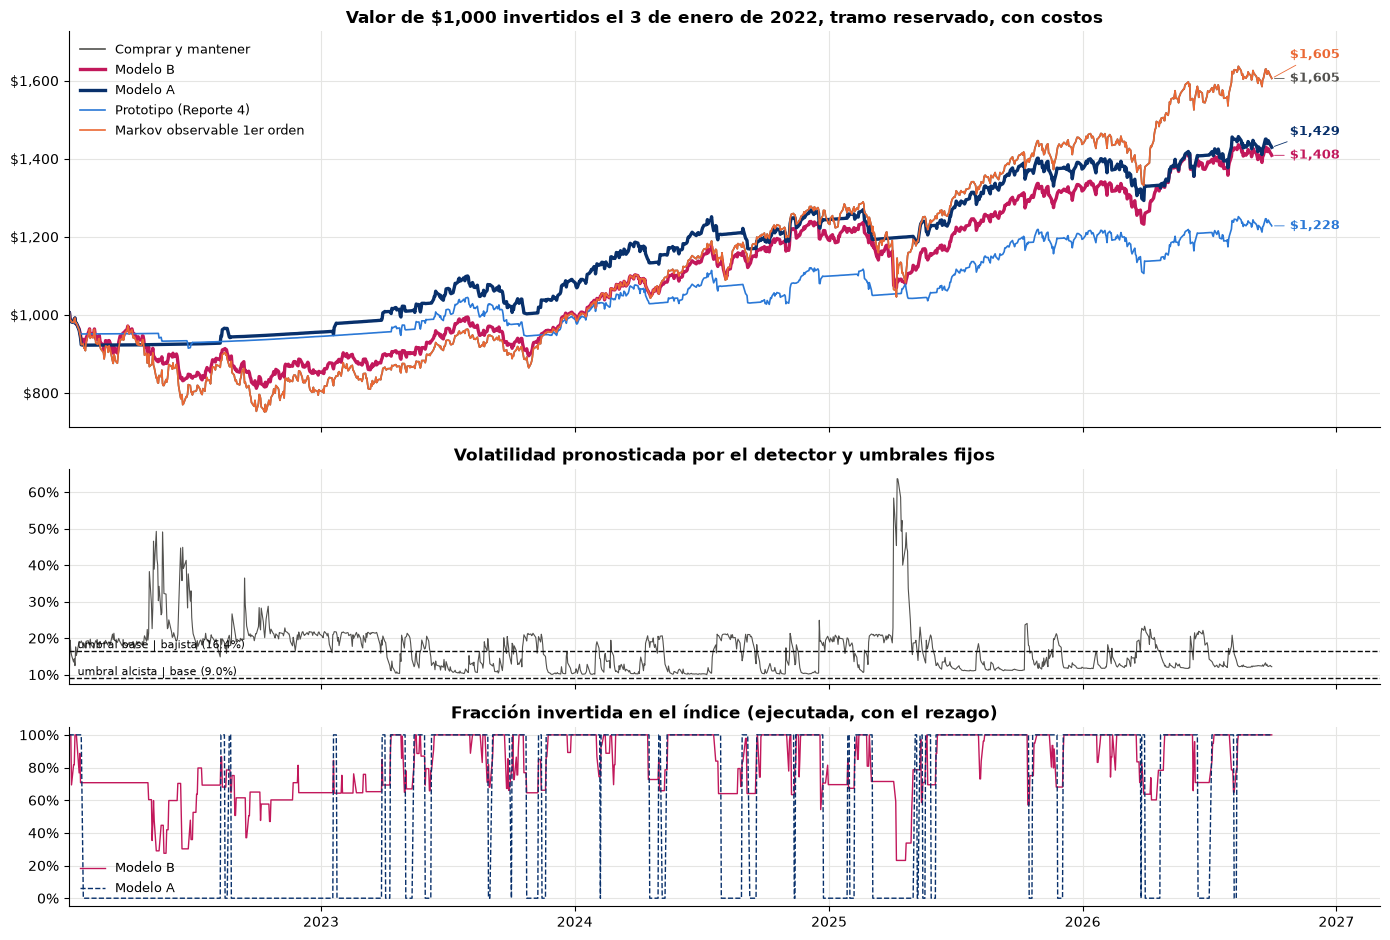

In [21]:
COLS_R = ["valor final", "rend. anual", "vol. anual", "Sharpe", "caída máxima", "cambios de posición"]
FMT_R = {**{ETIQ[c]: FMT_RES[c] for c in COLS_R}, "PSR (aislado)": "{:.2f}"}
for c in ["con costos", "sin costos"]:
    print(f"Tabla E.1{'a' if c == 'con costos' else 'b'}. Tramo reservado, {c}")
    t = tab_r[c].loc[FINALES, COLS_R + ["PSR (aislado)"]].rename(columns=ETIQ)
    display(t.style.format(FMT_R).apply(lambda r: ["font-weight: bold" if r.name in ("Modelo A", "Modelo B") else "" for _ in r], axis=1))

COMP = ["Comprar y mantener", "Modelo B", "Modelo A"]
lado = pd.concat({"Desarrollo 1990–2021": tab["con costos"].loc[COMP, ["vol. anual", "Sharpe", "caída máxima", "exposición media"]],
                  "Reservado 2022–2026": tab_r["con costos"].loc[COMP, ["vol. anual", "Sharpe", "caída máxima", "exposición media"]]}, axis=1)
for tramo in ["Desarrollo 1990–2021", "Reservado 2022–2026"]:
    lado[(tramo, "vol. contra el índice")] = lado[(tramo, "vol. anual")] / lado.loc["Comprar y mantener", (tramo, "vol. anual")] - 1
lado = lado.sort_index(axis=1, level=0, sort_remaining=False)
print("\nTabla E.2. ¿Se sostiene lo del desarrollo? (con costos)")
display(lado.style.format({col: ("{:.2f}" if col[1] == "Sharpe" else "{:+.0%}" if col[1] == "vol. contra el índice" else "{:.1%}")
                           for col in lado.columns}))

fig, ax = plt.subplots(3, 1, figsize=(14, 9.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.2, 1]})
grafica_valor(ax[0], {n: rr["con costos"][n][0] for n in FINALES},
              "Valor de $1,000 invertidos el 3 de enero de 2022, tramo reservado, con costos", resaltar=["Modelo A", "Modelo B"])
ax[1].plot(sig_r, color="#52514e", lw=0.8, label="volatilidad pronosticada")
for u, n in zip(UMBRALES, ["alcista | base", "base | bajista"]):
    ax[1].axhline(u, color="#0b0b0b", ls="--", lw=1)
    ax[1].text(sig_r.index[5], u, f" umbral {n} ({u:.1%})", va="bottom", fontsize=8)
ax[1].yaxis.set_major_formatter(pct); ax[1].set_title("Volatilidad pronosticada por el detector y umbrales fijos")
ax[2].plot(rr["con costos"]["Modelo B"][2], color=C_EST["Modelo B"], lw=1, label="Modelo B")
ax[2].plot(rr["con costos"]["Modelo A"][2], color=C_EST["Modelo A"], lw=1, ls="--", label="Modelo A")
ax[2].yaxis.set_major_formatter(pct); ax[2].set_ylim(-0.05, 1.05); ax[2].legend(loc="lower left", fontsize=9)
ax[2].set_title("Fracción invertida en el índice (ejecutada, con el rezago)")
plt.tight_layout(); plt.show()

## E.3 Comparación pareada del Sharpe (Ledoit y Wolf [16])

La misma prueba del Reporte 5: compara las estrategias día por día, de modo que el movimiento común del mercado se cancela. Con menos de cinco años, el error estándar será mayor que en el desarrollo.

In [22]:
tabla_lw_r = pd.DataFrame({(c, f"{a} − {b}"): ledoit_wolf(rr[c][a][1], rr[c][b][1]) for c in rr for a, b in PARES}).T
tabla_lw_r.index.names = ["costos", "comparación"]
print("Tabla E.3. Diferencias de Sharpe con la prueba pareada, tramo reservado")
display(tabla_lw_r.rename(columns={"Sharpe 1": "Sharpe de la primera", "Sharpe 2": "Sharpe de la segunda", "diferencia": "Diferencia",
                                   "EE pareado": "Error estándar pareado", "p-valor": "p-valor", "correlación": "Correlación diaria",
                                   "EE sin parear": "Error estándar sin parear"}).style.format(
    {"Sharpe de la primera": "{:.2f}", "Sharpe de la segunda": "{:.2f}", "Diferencia": "{:+.2f}", "Error estándar pareado": "{:.2f}",
     "p-valor": "{:.2f}", "Correlación diaria": "{:.2f}", "Error estándar sin parear": "{:.2f}"}))

Tabla E.3. Diferencias de Sharpe con la prueba pareada, tramo reservado


## E.4 ¿Podría ser suerte? PSR y Sharpe deflactado en el tramo reservado

El DSR exige que el Sharpe supere el umbral $SR_0$, el Sharpe que alcanzaría **por suerte** la mejor de las pruebas [14]:

$$SR_0 = \sqrt{V[\widehat{SR}]}\; \mathbb{E}\left[\max_{n \le N} Z_n\right], \qquad \mathrm{DSR} = \Phi\!\left(\frac{(\widehat{SR} - SR_0)\sqrt{T - 1}}{\sqrt{1 - \hat\gamma_3 \widehat{SR} + \frac{\hat\gamma_4 - 1}{4}\widehat{SR}^2}}\right)$$

En el tramo reservado, $V[\widehat{SR}]$ es la varianza con la que se estima un Sharpe **en una muestra de este largo** si no hay habilidad, $1/(T-1)$ en unidades diarias. Así, el umbral refleja que con menos datos la suerte puede producir Sharpe más altos. Se reportan tres versiones:

- **PSR (M = 1):** $SR_0 = 0$, como si sólo hubiéramos probado esa estrategia.
- **DSR (M = 2):** las dos estrategias que pasaron al tramo reservado, A y B. Para dos pruebas con correlación $\rho$ el máximo esperado es exacto: $\mathbb{E}[\max(Z_1, Z_2)] = \sqrt{(1 - \rho)/\pi}$.
- **DSR (M = 50):** la versión más exigente, como si se eligiera la mejor de toda la bitácora. Usa las 21.7 pruebas efectivas del desarrollo y la aproximación de Bailey y López de Prado [14].

In [23]:
GAMMA_EM = 0.5772156649


def dsr_con_umbral(ex, sr0):
    T, sr = len(ex), ex.mean() / ex.std()
    den = np.sqrt(1 - stats.skew(ex) * sr + (stats.kurtosis(ex, fisher=False) - 1) / 4 * sr ** 2)
    return stats.norm.cdf((sr - sr0) * np.sqrt(T - 1) / den)


def max_esperado(n_ef):
    return (1 - GAMMA_EM) * stats.norm.ppf(1 - 1 / n_ef) + GAMMA_EM * stats.norm.ppf(1 - 1 / (n_ef * np.e))


ex_A, ex_B = rr["con costos"]["Modelo A"][1], rr["con costos"]["Modelo B"][1]
rho_AB = np.corrcoef(ex_A, ex_B)[0, 1]
de_sr = np.sqrt(1 / (T_r - 1))
info50 = sharpe_deflactado(EX["con costos"].iloc[:, 0], EX["con costos"])
UMBRAL_SR0 = {"PSR (M = 1)": 0.0,
              "DSR (M = 2)": de_sr * np.sqrt((1 - rho_AB) / np.pi),
              "DSR (M = 50)": de_sr * max_esperado(info50["pruebas efectivas"])}
print(f"Umbral SR0 anual: " + " | ".join(f"{k}: {v * np.sqrt(252):.2f}" for k, v in UMBRAL_SR0.items())
      + f"  (correlación A–B {rho_AB:.2f}; {info50['pruebas efectivas']:.1f} pruebas efectivas en la bitácora)")

filas = {}
for c in rr:
    for n in ["Modelo B", "Modelo A", "Comprar y mantener"]:
        ex = rr[c][n][1]
        filas[(c, n)] = {"Sharpe": ex.mean() / ex.std() * np.sqrt(252), **{k: dsr_con_umbral(ex, v) for k, v in UMBRAL_SR0.items()}}
tabla_dsr_r = pd.DataFrame(filas).T
tabla_dsr_r.index.names = ["costos", "estrategia"]
print("Tabla E.4. Probabilidad de que el Sharpe sea real, tramo reservado (criterio usual: 0.95)")
print("Comprar y mantener no es una prueba nuestra: se muestra sólo como referencia.")
display(tabla_dsr_r.style.format("{:.2f}"))

Umbral SR0 anual: PSR (M = 1): 0.00 | DSR (M = 2): 0.14 | DSR (M = 50): 0.89  (correlación A–B 0.71; 21.7 pruebas efectivas en la bitácora)
Tabla E.4. Probabilidad de que el Sharpe sea real, tramo reservado (criterio usual: 0.95)
Comprar y mantener no es una prueba nuestra: se muestra sólo como referencia.


## E.5 ¿Cómo vio el detector al mercado de 2022–2026?

**Por qué lo preguntamos.** En el desarrollo, la escala fija de 1950–1989 resultó tranquila: sólo 2% de los días fueron alcistas y 36% bajistas (Q1). Si el mercado de 2022–2026 fue más agitado o más tranquilo, eso explica cuánto tiempo pasa A fuera del índice y cuánto invierte B.

In [24]:
rs_lag_r = r_simple.shift(-H).reindex(et_r.index)


def perfil(et, r):
    return {**{f"% días {n}": (et == i).mean() for i, n in enumerate(NOMBRES)},
            "vol. del índice en bajista": r[et == 2].std() * np.sqrt(252),
            "rend. del índice en bajista": r[et == 2].mean() * 252,
            "rend. del índice en base": r[et == 1].mean() * 252}


perfiles = pd.DataFrame({"Desarrollo 1990–2021": perfil(et_anc, rs_lag), "Reservado 2022–2026": perfil(et_r, rs_lag_r)}).T
perfiles["exposición media de B"] = [tab["con costos"].loc["Modelo B", "exposición media"], tab_r["con costos"].loc["Modelo B", "exposición media"]]
perfiles["días de A en el índice"] = [tab["con costos"].loc["Modelo A", "% comprado"], tab_r["con costos"].loc["Modelo A", "% comprado"]]
print("Tabla E.5. Etiquetas ancladas y exposición de los modelos, desarrollo contra reservado")
display(perfiles.style.format({c: ("{:+.1%}" if c.startswith("rend.") else "{:.0%}" if c.startswith(("%", "exposición", "días")) else "{:.1%}")
                               for c in perfiles.columns}))

Tabla E.5. Etiquetas ancladas y exposición de los modelos, desarrollo contra reservado


,% días alcista,% días base,% días bajista,vol. del índice en bajista,rend. del índice en bajista,rend. del índice en base,exposición media de B,días de A en el índice
Desarrollo 1990–2021,2%,62%,36%,25.5%,+11.4%,+9.3%,86%,67%
Reservado 2022–2026,0%,52%,48%,21.4%,+12.5%,+10.3%,82%,59%


## E.6 Episodios de caída

**Por qué lo preguntamos.** En el desarrollo, los modelos protegieron mucho en la crisis de 2008 (rápida y muy volátil) y poco en 2000–2003 (lenta). El tramo reservado incluye caídas de los dos tipos, así que es un experimento natural para H4 y H5. Los episodios no se eligen a mano: los define la regla de E.0 (caída de al menos 10% desde el máximo previo).

**Cómo se lee.** *Retraso* son los días hábiles desde el máximo hasta que la posición ejecutada se pone a la defensiva (A en T-bills; B por debajo de 100%); si B ya estaba por debajo de 100% en el máximo, su retraso es 0, y por eso se muestra también su exposición en el máximo y la mínima del episodio. *Protección* es la fracción de la caída del índice que la estrategia se ahorró.

Tabla E.6. Episodios en que el índice cayó al menos 10% desde su máximo, con costos (rebote: 63 días hábiles después del mínimo)


Máximo,Mínimo,Recuperación,Días al mínimo,Caída del índice,Velocidad (%/día),Caída A,Protección A,Retraso A,Caída B,Protección B,Retraso B,Exposición B en el máximo,Exposición B mínima,Rebote índice,Rebote A,Rebote B
2022-01-03,2022-10-12,2024-01-19,195,-25.4%,0.13%,-8.4%,67%,14,-19.4%,24%,4,100%,28%,+11.4%,+1.0%,+7.3%
2025-02-19,2025-04-08,2025-06-27,34,-18.9%,0.56%,-6.0%,68%,10,-13.5%,28%,4,100%,23%,+26.0%,+7.8%,+14.5%


— en Retraso: no se puso a la defensiva durante la caída. — en Rebote: el mínimo quedó a menos de 63 días hábiles del fin del tramo.


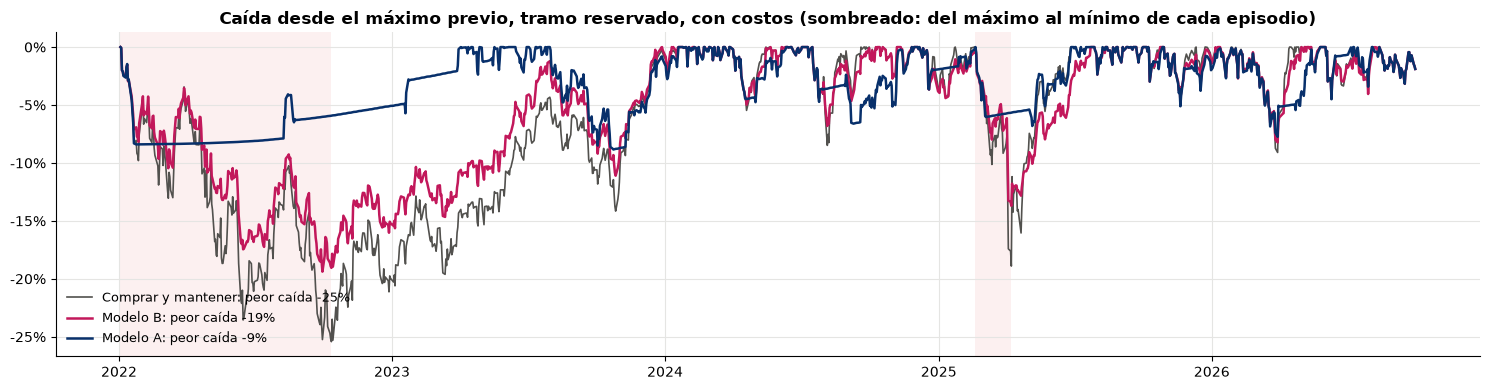

In [25]:
def episodios_caida(riqueza, umbral):
    # Tramos entre máximos sucesivos en que la caída desde el máximo llega al umbral
    dd = riqueza / riqueza.cummax() - 1
    grupo = (riqueza >= riqueza.cummax()).cumsum()
    eps = []
    for g, tramo in dd.groupby(grupo):
        if tramo.min() <= -umbral:
            sig_max = grupo.index[grupo > g]
            eps.append({"máximo": tramo.index[0], "mínimo": tramo.idxmin(), "caída del índice": tramo.min(),
                        "recuperación": sig_max[0] if len(sig_max) else pd.NaT})
    return pd.DataFrame(eps)


riq_r = {n: INICIAL * (1 + rr["con costos"][n][0]).cumprod() for n in FINALES}
w_r = {n: rr["con costos"][n][2] for n in FINALES}
eps_r = episodios_caida(riq_r["Comprar y mantener"], CRITERIOS["caida_episodio"])
filas = []
for _, e in eps_r.iterrows():
    a, b = e["máximo"], e["mínimo"]
    dias = len(riq_r["Comprar y mantener"][a:b]) - 1
    fila = {"Máximo": f"{a:%Y-%m-%d}", "Mínimo": f"{b:%Y-%m-%d}",
            "Recuperación": "sin recuperar" if pd.isna(e["recuperación"]) else f"{e['recuperación']:%Y-%m-%d}",
            "Días al mínimo": dias, "Caída del índice": e["caída del índice"], "Velocidad (%/día)": -e["caída del índice"] / max(dias, 1)}
    despues = riq_r["Comprar y mantener"].index[riq_r["Comprar y mantener"].index > b][:CRITERIOS["dias_rebote"]]
    for n, corto, defensa in [("Modelo A", "A", lambda w: w == 0), ("Modelo B", "B", lambda w: w < 1)]:
        tramo = riq_r[n][a:b]
        caida = (tramo / tramo.iloc[0]).min() - 1
        fila[f"Caída {corto}"] = caida
        fila[f"Protección {corto}"] = 1 - caida / e["caída del índice"]
        enf = defensa(w_r[n][a:b])
        fila[f"Retraso {corto}"] = int(np.argmax(enf.values)) if enf.any() else np.nan
    fila["Exposición B en el máximo"] = w_r["Modelo B"][a]
    fila["Exposición B mínima"] = w_r["Modelo B"][a:b].min()
    for n, corto in [("Comprar y mantener", "índice"), ("Modelo A", "A"), ("Modelo B", "B")]:   # sólo con los 63 días completos
        fila[f"Rebote {corto}"] = (riq_r[n][despues[-1]] / riq_r[n][b] - 1) if len(despues) == CRITERIOS["dias_rebote"] else np.nan
    filas.append(fila)
tabla_eps = pd.DataFrame(filas)
print(f"Tabla E.6. Episodios en que el índice cayó al menos {CRITERIOS['caida_episodio']:.0%} desde su máximo, con costos "
      f"(rebote: {CRITERIOS['dias_rebote']} días hábiles después del mínimo)")
if len(tabla_eps):
    fmt = {c: "{:+.1%}" for c in tabla_eps.columns if c.startswith(("Caída", "Rebote"))}
    fmt.update({c: "{:.0%}" for c in tabla_eps.columns if c.startswith(("Protección", "Exposición"))})
    fmt.update({c: "{:.0f}" for c in tabla_eps.columns if c.startswith("Retraso")})
    fmt["Velocidad (%/día)"] = "{:.2%}"
    display(tabla_eps.style.format(fmt, na_rep="—").hide(axis="index"))
    print("— en Retraso: no se puso a la defensiva durante la caída. — en Rebote: el mínimo quedó a menos de 63 días hábiles del fin del tramo.")
else:
    print("No hubo episodios que cumplan la regla.")

fig, ax = plt.subplots(figsize=(15, 4))
for n in ["Comprar y mantener", "Modelo B", "Modelo A"]:
    caida = riq_r[n] / riq_r[n].cummax() - 1
    ax.plot(caida, color=C_EST[n], lw=1.8 if n != "Comprar y mantener" else 1.2, label=f"{n}: peor caída {caida.min():.0%}")
for _, e in eps_r.iterrows():
    ax.axvspan(e["máximo"], e["mínimo"], color="#e34948", alpha=0.08, lw=0)
ax.yaxis.set_major_formatter(pct); ax.legend(loc="lower left", fontsize=9)
ax.set_title("Caída desde el máximo previo, tramo reservado, con costos (sombreado: del máximo al mínimo de cada episodio)")
plt.tight_layout(); plt.show()

## E.7 Veredicto de las hipótesis

Cada hipótesis se evalúa con el criterio exacto que se declaró en E.0, sin reinterpretarlo.

In [26]:
cc_r = tab_r["con costos"]
lw_cc = tabla_lw_r.loc["con costos"]


def no_peor(par):
    d = lw_cc.loc[par]
    return not (d["diferencia"] < 0 and d["p-valor"] < CRITERIOS["alfa"])


def riesgo(n):
    return (cc_r.loc[n, "vol. anual"] < cc_r.loc["Comprar y mantener", "vol. anual"]
            and cc_r.loc[n, "caída máxima"] > cc_r.loc["Comprar y mantener", "caída máxima"])


filas = {}
for h, n in [("H1", "Modelo B"), ("H3", "Modelo A")]:
    filas[h] = {"se cumple": riesgo(n),
                "observado": f"vol. {cc_r.loc[n, 'vol. anual']:.1%} contra {cc_r.loc['Comprar y mantener', 'vol. anual']:.1%}; "
                             f"caída {cc_r.loc[n, 'caída máxima']:.1%} contra {cc_r.loc['Comprar y mantener', 'caída máxima']:.1%}"}
d = lw_cc.loc["Modelo B − Comprar y mantener"]
filas["H2"] = {"se cumple": no_peor("Modelo B − Comprar y mantener"), "observado": f"diferencia {d['diferencia']:+.2f}, p = {d['p-valor']:.2f}"}
reb = tabla_eps.dropna(subset=["Rebote A", "Rebote índice"]) if len(tabla_eps) else tabla_eps
if len(reb):
    pierde = (reb["Rebote A"] < reb["Rebote índice"])
    filas["H4"] = {"se cumple": pierde.mean() > 0.5, "observado": f"A rinde menos en {pierde.sum()} de {len(pierde)} rebotes"}
else:
    filas["H4"] = {"se cumple": np.nan, "observado": "sin episodios con rebote completo"}
if len(tabla_eps) >= 2:
    rap, len_ = tabla_eps["Velocidad (%/día)"].idxmax(), tabla_eps["Velocidad (%/día)"].idxmin()
    ok = [tabla_eps.loc[rap, f"Protección {k}"] > tabla_eps.loc[len_, f"Protección {k}"] for k in "AB"]
    filas["H5"] = {"se cumple": all(ok) if all(ok) or not any(ok) else "parcial",
                   "observado": f"rápido ({tabla_eps.loc[rap, 'Máximo']}): A {tabla_eps.loc[rap, 'Protección A']:.0%}, "
                                f"B {tabla_eps.loc[rap, 'Protección B']:.0%} | lento ({tabla_eps.loc[len_, 'Máximo']}): "
                                f"A {tabla_eps.loc[len_, 'Protección A']:.0%}, B {tabla_eps.loc[len_, 'Protección B']:.0%}"}
else:
    filas["H5"] = {"se cumple": np.nan, "observado": "menos de dos episodios: no se puede comparar"}
d = lw_cc.loc["Modelo A − Modelo B"]
filas["H6"] = {"se cumple": cc_r.loc["Modelo B", "Sharpe"] >= cc_r.loc["Modelo A", "Sharpe"],
               "observado": f"Sharpe B {cc_r.loc['Modelo B', 'Sharpe']:.2f} contra A {cc_r.loc['Modelo A', 'Sharpe']:.2f} "
                            f"(p = {d['p-valor']:.2f})"}
veredicto = pd.DataFrame(filas).T.loc[list(HIPOTESIS)]
veredicto.insert(0, "hipótesis", [HIPOTESIS[h] for h in veredicto.index])
veredicto["se cumple"] = veredicto["se cumple"].map(lambda v: v if isinstance(v, str) else ("sí" if v else "no")
                                                     if isinstance(v, (bool, np.bool_)) else "no aplica")
print(f"Tabla E.7. Veredicto (hipótesis con huella {huella_hip})")
display(veredicto.style.set_properties(**{"text-align": "left"}))

Tabla E.7. Veredicto (hipótesis con huella 1748603832)


,hipótesis,se cumple,observado
H1,B reduce el riesgo: volatilidad anual y caída máxima menores que las del índice (con costos),sí,vol. 12.3% contra 17.2%; caída -19.4% contra -25.4%
H2,"B no sacrifica Sharpe: la diferencia B − índice no es negativa con p menor que 0.05 (Ledoit y Wolf, con costos)",sí,"diferencia -0.11, p = 0.30"
H3,A reduce el riesgo: volatilidad anual y caída máxima menores que las del índice (con costos),sí,vol. 9.6% contra 17.2%; caída -8.8% contra -25.4%
H4,A se pierde los rebotes: en la mayoría de los episodios rinde menos que el índice en los 63 días tras el mínimo,sí,A rinde menos en 2 de 2 rebotes
H5,Más protección en caídas rápidas: la de A y la de B son mayores en el episodio más rápido que en el más lento,sí,"rápido (2025-02-19): A 68%, B 28% | lento (2022-01-03): A 67%, B 24%"
H6,B es al menos tan bueno como A: Sharpe de B ≥ Sharpe de A (con costos),no,Sharpe B 0.33 contra A 0.42 (p = 0.78)


### Lectura del tramo reservado

*Esta celda se escribe **después** de correr, con las cifras reales. Guía para no dejar fuera nada:*

- **El resultado central.** ¿B sostuvo lo del desarrollo (mismo Sharpe que el índice con menos riesgo)? Citar las tablas E.1, E.2 y E.3.
- **A contra B.** ¿Se repitió el orden del desarrollo? ¿Por qué (exposición, rebotes)?
- **Las caídas (E.6).** Qué pasó en cada episodio. ¿Se confirma que el detector protege más en caídas rápidas (H5)? ¿Cuánto tardó en ponerse a la defensiva?
- **La escala anclada (E.5).** ¿El mercado de 2022–2026 fue más o menos agitado que el de 1990–2021 según el detector? ¿Cómo afectó eso a A?
- **Suerte (E.4).** Reportar el PSR y los dos DSR, recordando que lo anticipamos en E.0: con menos de cinco años no se puede descartar la suerte con ese criterio.
- **Hipótesis que no se cumplieron.** Decirlo claramente y no buscar una variante que las rescate: cualquier cambio después de abrir el tramo ya no es un examen limpio.

In [27]:
guardar_r = {"version": "v7", "huella_regla": huella_regla, "huella_hipotesis": huella_hip, "huella_datos": huella,
             "aperturas": len(previas) + 1, "inicio": ini_r, "fin": fin_r, "HIPOTESIS": HIPOTESIS, "CRITERIOS": CRITERIOS,
             "rendimientos": {c: {n: v[0] for n, v in r.items()} for c, r in rr.items()},
             "excesos": {c: {n: v[1] for n, v in r.items()} for c, r in rr.items()},
             "posiciones": {c: {n: v[2] for n, v in r.items()} for c, r in rr.items()},
             "tabla": tab_r, "tabla_desarrollo": tab, "ledoit_wolf": tabla_lw_r, "ledoit_wolf_desarrollo": tabla_lw,
             "dsr": tabla_dsr_r, "umbral_sr0": UMBRAL_SR0, "episodios": tabla_eps, "perfiles": perfiles,
             "veredicto": veredicto, "vol_pronosticada": sig_r, "umbrales": UMBRALES, "vol_objetivo": pB["vol_objetivo"],
             # Desarrollo 1990–2021 de las tres estrategias que compara el notebook de otros activos (las mismas series del Reporte 5)
             "desarrollo": {"rendimientos": {c: {n: res[c][n][0] for n in COMP} for c in res},
                            "excesos": {c: {n: res[c][n][1] for n in COMP} for c in res},
                            "posiciones": {c: {n: res[c][n][2] for n in COMP} for c in res},
                            "vol_pronosticada": sig}}
with open("resultados_reservado_v7.pkl", "wb") as f:
    pickle.dump(guardar_r, f)
print("Guardado resultados_reservado_v7.pkl (lo usa 03_Comparativa_Multiactivo)")

Guardado resultados_reservado_v7.pkl (lo usa 03_Comparativa_Multiactivo)


## Bibliografía

[1] L. R. Rabiner, "A tutorial on hidden Markov models and selected applications in speech recognition," *Proceedings of the IEEE*, vol. 77, no. 2, pp. 257–286, 1989. http://www.cs.ubc.ca/~murphyk/Bayes/rabiner.pdf

[6] D. H. Bailey, J. M. Borwein, M. López de Prado y Q. J. Zhu, "Pseudo-mathematics and financial charlatanism," *Notices of the AMS*, vol. 61, no. 5, pp. 458–471, 2014. https://www.ams.org/journals/notices/201405/rnoti-p458.pdf

[9] J. Bulla, S. Mergner, I. Bulla, A. Sesboüé y C. Chesneau, "Markov-switching asset allocation: Do profitable strategies exist?," *Journal of Asset Management*, vol. 12, no. 5, pp. 310–321, 2011. https://mpra.ub.uni-muenchen.de/21154/

[11] J. Bulla, "Hidden Markov models with t components. Increased persistence and other aspects," *Quantitative Finance*, vol. 11, no. 3, pp. 459–475, 2011. https://mpra.ub.uni-muenchen.de/21830/1/MPRA_paper_21830.pdf

[14] D. H. Bailey y M. López de Prado, "The deflated Sharpe ratio," *Journal of Portfolio Management*, vol. 40, no. 5, pp. 94–107, 2014. http://www.davidhbailey.com/dhbpapers/deflated-sharpe.pdf

[15] A. Moreira y T. Muir, "Volatility-managed portfolios," *Journal of Finance*, vol. 72, no. 4, pp. 1611–1644, 2017. Versión de trabajo: NBER Working Paper 22208. https://www.nber.org/papers/w22208

[16] O. Ledoit y M. Wolf, "Robust performance hypothesis testing with the Sharpe ratio," *Journal of Empirical Finance*, vol. 15, no. 5, pp. 850–859, 2008.

[17] S. Cederburg, M. S. O'Doherty, F. Wang y X. S. Yan, "On the performance of volatility-managed portfolios," *Journal of Financial Economics*, vol. 138, no. 1, pp. 95–117, 2020.

La numeración sigue la del v5.1; las referencias que no se citan en este notebook se omiten.
